# SkinDisNet EDA (two dataset folders, each with augmented / preprocessed / metadata)
Same workflow as the scabies notebook (dataset EDA, then preprocessing comparison, then the two extra checks), adapted for:
- **two root folders** (`SkinDisNet_2` and `SkinDisNet`), each with `augmented`, `preprocessed` and `metadata` sub-folders
- **class labels read from sub-folder names** (falls back to the metadata CSV if images are not in class folders)
- **augmentation-aware checks**: augmented copies of the same photo must never be split across train and test

Run the cells top to bottom. **Cell 1 only inspects the folders**: read what it prints, and if anything was detected wrongly, set the override variables in Cell 2.

In [1]:
import os, glob, re, hashlib, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
warnings.filterwarnings("ignore")

BASE = "/Users/macbook/Desktop/projects/SkinDisNet A Multi-Class Clinical Images and Metad"
ROOTS = {"SkinDisNet_2": os.path.join(BASE, "SkinDisNet_2"),
         "SkinDisNet":   os.path.join(BASE, "SkinDisNet")}
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")

# ---------- inspect the folder structure ----------
for name, root in ROOTS.items():
    assert os.path.isdir(root), f"Folder not found: {root}"
    print("=" * 70); print(name, "->", root)
    for sub in sorted(os.listdir(root)):
        p = os.path.join(root, sub)
        if not os.path.isdir(p): print("  (file)", sub); continue
        files = [f for f in glob.glob(os.path.join(p, "**", "*"), recursive=True) if os.path.isfile(f)]
        imgs = [f for f in files if f.lower().endswith(IMG_EXTS)]
        others = [f for f in files if not f.lower().endswith(IMG_EXTS)]
        kids = sorted(d for d in os.listdir(p) if os.path.isdir(os.path.join(p, d)))
        print(f"  {sub:20s} images: {len(imgs):6d} | other files: {len(others):3d} | sub-folders: {len(kids)}")
        for k in kids[:12]:
            n_k = len([f for f in glob.glob(os.path.join(p, k, "**", "*"), recursive=True) if f.lower().endswith(IMG_EXTS)])
            print(f"      - {k}  ({n_k} images)")
        if others: print("      other files e.g.:", [os.path.basename(o) for o in others[:4]])

SkinDisNet_2 -> /Users/macbook/Desktop/projects/SkinDisNet A Multi-Class Clinical Images and Metad/SkinDisNet_2
  Augmented            images:  11970 | other files:   0 | sub-folders: 6
      - Atopic Dermatitis (AD)  (490 images)
      - Contact Dermatitis (CD)  (3339 images)
      - Eczema (EC)  (3262 images)
      - Scabies (SC)  (2401 images)
      - Seborrheic Dermatitis (SD)  (553 images)
      - Tinea Corporis (TC)  (1925 images)
  Preprocessed         images:   1710 | other files:   0 | sub-folders: 6
      - Atopic Dermatitis (AD)  (70 images)
      - Contact Dermatitis (CD)  (477 images)
      - Eczema (EC)  (466 images)
      - Scabies (SC)  (343 images)
      - Seborrheic Dermatitis (SD)  (79 images)
      - Tinea Corporis (TC)  (275 images)
  (file) SkinDisNet_Metadata.csv
SkinDisNet -> /Users/macbook/Desktop/projects/SkinDisNet A Multi-Class Clinical Images and Metad/SkinDisNet
  Augmented            images:  11970 | other files:   0 | sub-folders: 6
      - AD  (490 imag

In [2]:
# ---------- settings ----------
SIZE = (512, 512)
OUT = "eda_skindisnet"                      # ONE output folder for everything
FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True)
RESIZE_MODE = "crop"          # "crop" | "pad" | "stretch"  (used in Part B only)
SEED = 42; rng = np.random.default_rng(SEED)
MAX_PER_GROUP = None          # e.g. 500 to test quickly; None = use every image
PARTB_MAX = None              # max images for Part B (None = all of the chosen group)

# How folder names are mapped to a "stage" (case-insensitive substring match)
STAGE_KEYS = {"augment": "augmented", "preprocess": "preprocessed", "meta": "metadata"}

# ---- overrides: leave None to auto-detect, set only if Cell 1 / the detection printout looks wrong ----
ID_COL = None                 # metadata column holding the image file name
LABEL_COL = None              # metadata column holding the class label
PATIENT_COL = None            # metadata column holding a patient id (if there is one)
# Regex removed from an augmented file's name to find the photo it came from (used for leakage-safe grouping)
# Regex removed (once, at the end of the name) from an augmented file's name to find the photo it came from.
# Default handles "SD (37)_02" -> "SD (37)" and "TC_200_06" -> "TC_200", plus word suffixes like "_aug3" / "_flip".
AUG_SUFFIX_RE = r"[_\-\s]?(aug|augmented|flip|flipped|rot|rotate|rotated|noise|bright|zoom|shear|crop)[\w\-]*$|_\d{1,3}$"
PREP_SUFFIX_RE = r"[_\-\s]?(prep|pre|preprocessed|resized|processed|clahe)[\w\-]*$"
LINK_DIST = 4       # dHash distance (of 64) at or below which two same-class images are treated as the same photo when building leakage-safe groups

def canon_label(x):
    """'Atopic Dermatitis (AD)' and 'AD' -> 'AD' (the two datasets name their class folders differently)."""
    x = str(x).strip(); m = re.search(r"\(([A-Za-z]{1,8})\)\s*$", x)
    return m.group(1).upper() if m else x

def stage_of(folder):
    f = folder.lower()
    for k, v in STAGE_KEYS.items():
        if k in f: return v
    return folder

# ---------- build the image table ----------
rows, meta_files = [], []
for dsname, root in ROOTS.items():
    for sub in sorted(os.listdir(root)):
        p = os.path.join(root, sub)
        if not os.path.isdir(p):
            if p.lower().endswith((".csv", ".xlsx", ".xls")): meta_files.append((dsname, p))      # metadata file sitting directly in the dataset folder
            continue
        stage = stage_of(sub)
        for f in glob.glob(os.path.join(p, "**", "*"), recursive=True):
            if not os.path.isfile(f): continue
            if stage == "metadata":
                if f.lower().endswith((".csv", ".xlsx", ".xls")): meta_files.append((dsname, f))
                continue
            if not f.lower().endswith(IMG_EXTS): continue
            parts = os.path.relpath(f, p).split(os.sep)
            rows.append(dict(dataset=dsname, stage=stage, folder_class=parts[0] if len(parts) > 1 else None,
                             path=f, Image_id=os.path.basename(f)))
T = pd.DataFrame(rows)
T["group"] = T.dataset + " | " + T.stage
T["stem"] = T.Image_id.str.replace(r"\.[A-Za-z]+$", "", regex=True)
T["stem_l"] = T.stem.str.lower().str.strip()
sfx = {"augmented": AUG_SUFFIX_RE, "preprocessed": PREP_SUFFIX_RE}
T["source_id"] = [re.sub(sfx[s], "", st, count=1, flags=re.I) if s in sfx else st for s, st in zip(T.stage, T.stem)]
T["source_l"] = T.source_id.str.lower().str.strip()
if MAX_PER_GROUP:
    T = T.groupby("group", group_keys=False).apply(lambda g: g.sample(min(len(g), MAX_PER_GROUP), random_state=SEED))
T = T.reset_index(drop=True); T.index.name = "uid"
print("images found per group:"); display(T.groupby("group").size().rename("images").to_frame())
print("metadata files:", [(d, os.path.basename(f)) for d, f in meta_files])

# ---------- load and auto-detect metadata ----------
def read_any(f):
    if f.lower().endswith(".csv"):
        for enc in ("utf-8", "utf-8-sig", "latin-1"):
            try: return pd.read_csv(f, encoding=enc)
            except Exception: pass
    return pd.read_excel(f)
M = []
for dsname, f in meta_files:
    m = read_any(f); m.columns = [str(c).strip() for c in m.columns]
    m["meta_dataset"] = dsname; m["meta_file"] = os.path.basename(f); M.append(m)
    print(f"\n{dsname} / {os.path.basename(f)}: {m.shape} | columns: {list(m.columns)}")
M = pd.concat(M, ignore_index=True) if M else pd.DataFrame()

def norm_key(s): return s.astype(str).str.strip().str.replace(r"\.[A-Za-z]+$", "", regex=True).str.lower()
if len(M):
    all_keys = set(T.stem_l) | set(T.source_l)
    if ID_COL is None:
        best, best_frac = None, 0
        for c in M.columns:
            if pd.api.types.is_numeric_dtype(M[c]): continue
            frac = norm_key(M[c].dropna()).isin(all_keys).mean() if M[c].notna().any() else 0
            if frac > best_frac: best, best_frac = c, frac
        ID_COL = best if best_frac > 0.2 else None
        print(f"\nauto-detected ID_COL = {ID_COL!r} ({best_frac * 100:.0f}% of its values match an image name)")
    if LABEL_COL is None:
        cand = [c for c in M.columns if not pd.api.types.is_numeric_dtype(M[c]) and 2 <= M[c].nunique() <= 60 and c not in (ID_COL, "meta_dataset", "meta_file")]
        pref = [c for c in cand if re.search(r"class|label|disease|diagnos|condition|categor", c, re.I)]
        LABEL_COL = (pref or cand or [None])[0]
        print(f"auto-detected LABEL_COL = {LABEL_COL!r}")
    if PATIENT_COL is None:
        pc = [c for c in M.columns if re.search(r"patient|subject|person", c, re.I)]
        PATIENT_COL = pc[0] if pc else None
        print(f"auto-detected PATIENT_COL = {PATIENT_COL!r}")
    if ID_COL:
        M["key"] = norm_key(M[ID_COL])
        Mr = M.rename(columns={c: f"m_{c}" for c in M.columns if c != "key"})
        vcols = [c for c in Mr.columns if c not in ("key", "m_meta_dataset")]
        Mu = Mr.drop_duplicates(["m_meta_dataset", "key"]).rename(columns={"m_meta_dataset": "dataset"})
        # match order: 1) same dataset + same file name  2) same dataset + source photo name
        # (never across datasets by name: the two folders number the same photos differently; cross-dataset sharing is done by image content later)
        A = T[["dataset", "stem_l"]].merge(Mu.rename(columns={"key": "stem_l"}), on=["dataset", "stem_l"], how="left")
        B = T[["dataset", "source_l"]].merge(Mu.rename(columns={"key": "source_l"}), on=["dataset", "source_l"], how="left")
        for X in (A, B): X.index = T.index
        MF = A[vcols].combine_first(B[vcols])
        T = T.join(MF)
        T.index.name = "uid"
        print("metadata matched (by name) per dataset:"); display((T.groupby("dataset")["m_" + ID_COL].apply(lambda s_: s_.notna().mean() * 100)).round(1).rename("% matched").to_frame())
else:
    print("\nno metadata tables found")

# ---------- final label: folder name first, then metadata; full names and codes are merged ("Eczema (EC)" and "EC" -> "EC") ----------
T["label_raw"] = T.folder_class
T["label"] = T.folder_class.map(lambda v: canon_label(v) if isinstance(v, str) else None)
if LABEL_COL and f"m_{LABEL_COL}" in T.columns:
    mlab = T[f"m_{LABEL_COL}"].map(lambda v: canon_label(v) if isinstance(v, str) else None)
    both = T.label.notna() & mlab.notna()
    if both.any(): print(f"folder label agrees with metadata label on {(T.label[both].str.lower() == mlab[both].str.lower()).mean() * 100:.1f}% of matched images")
    T["label"] = T["label"].fillna(mlab)
T["label"] = T["label"].fillna("unknown")
if PATIENT_COL and f"m_{PATIENT_COL}" in T.columns:
    T["patient"] = T[f"m_{PATIENT_COL}"].astype(str)
else:
    T["patient"] = T["source_id"]            # best available: the photo an image was derived from
print("\nclasses:", sorted(T.label.unique()))
names = T.dropna(subset=["label_raw"]).drop_duplicates(["label", "label_raw"])
print("class folder names merged into each label:"); display(names.groupby("label").label_raw.apply(lambda s_: sorted(set(s_))).to_frame("folder names"))
print("per-dataset grouping key:", "patient column" if PATIENT_COL else "source photo name (no patient column found); content-based linking across datasets is done in the duplicates cell")
print("distinct source photos (name-based, per dataset):", T.groupby("dataset").source_l.nunique().to_dict(), "| images:", len(T))

images found per group:


,images
group,
SkinDisNet | augmented,11970
SkinDisNet | preprocessed,1710
SkinDisNet_2 | augmented,11970
SkinDisNet_2 | preprocessed,1710


metadata files: [('SkinDisNet_2', 'SkinDisNet_Metadata.csv')]

SkinDisNet_2 / SkinDisNet_Metadata.csv: (1710, 9) | columns: ['Folder_name', 'Patient_id', 'Image_id', 'Age', 'Sex', 'Leision_location', 'Diagnosis', 'meta_dataset', 'meta_file']

auto-detected ID_COL = 'Image_id' (100% of its values match an image name)
auto-detected LABEL_COL = 'Diagnosis'
auto-detected PATIENT_COL = 'Patient_id'
metadata matched (by name) per dataset:


,% matched
dataset,
SkinDisNet,0.0
SkinDisNet_2,100.0


folder label agrees with metadata label on 0.0% of matched images

classes: ['AD', 'CD', 'EC', 'SC', 'SD', 'TC']
class folder names merged into each label:


,folder names
label,
AD,"[AD, Atopic Dermatitis (AD)]"
CD,"[CD, Contact Dermatitis (CD)]"
EC,"[EC, Eczema (EC)]"
SC,"[SC, Scabies (SC)]"
SD,"[SD, Seborrheic Dermatitis (SD)]"
TC,"[TC, Tinea Corporis (TC)]"


per-dataset grouping key: patient column
distinct source photos (name-based, per dataset): {'SkinDisNet': 1710, 'SkinDisNet_2': 1710} | images: 27360


# Part A: dataset EDA
Every statistic is computed for each **dataset x stage** group (`SkinDisNet_2 | augmented`, `SkinDisNet_2 | preprocessed`, `SkinDisNet | augmented`, `SkinDisNet | preprocessed`), so you can see what augmentation and preprocessing did to the images and whether the two datasets differ.

In [3]:
# ---------- per-image statistics ----------
NK = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)   # Immerkaer noise kernel
def get_L(img): return cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[:, :, 0]
def metrics(L):
    f = L.astype(np.float32); H, W = f.shape
    p = np.bincount(L.ravel(), minlength=256) / L.size; p = p[p > 0]
    gx, gy = cv2.Sobel(f, cv2.CV_32F, 1, 0), cv2.Sobel(f, cv2.CV_32F, 0, 1)
    conv = cv2.filter2D(f, -1, NK)[1:-1, 1:-1]
    sigma = np.sqrt(np.pi / 2) * np.abs(conv).sum() / (6 * (H - 2) * (W - 2))
    return dict(contrast=f.std(), entropy=-(p * np.log2(p)).sum(), edge=np.hypot(gx, gy).mean(), noise=sigma)

THUMB = 128
recs, bad = [], []
mean_sum, mean_n = {}, {}                       # running sums for the mean image per (group, class)
for n, r in enumerate(T.itertuples()):
    img = cv2.imread(r.path)
    if img is None: bad.append(r.path); continue
    h, w = img.shape[:2]
    with Image.open(r.path) as im: fmt, mode = im.format, im.mode
    L = get_L(img); m = metrics(L); hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    with open(r.path, "rb") as fh: md5 = hashlib.md5(fh.read()).hexdigest()
    g9 = cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (9, 8), interpolation=cv2.INTER_AREA)
    dh = int("".join("1" if b else "0" for b in (g9[:, 1:] > g9[:, :-1]).ravel()), 2)
    recs.append(dict(uid=r.Index, width=w, height=h, aspect=w / h, format=fmt, mode=mode,
        file_kb=os.path.getsize(r.path) / 1024, md5=md5, dhash=dh,
        mean_L=L.mean(), contrast=m["contrast"], entropy=m["entropy"],
        sharpness=cv2.Laplacian(L, cv2.CV_64F).var(), edge=m["edge"], noise=m["noise"],
        R=img[:, :, 2].mean(), G=img[:, :, 1].mean(), B=img[:, :, 0].mean(),
        sat=hsv[:, :, 1].mean(), val=hsv[:, :, 2].mean(),
        dark_pct=(L < 20).mean() * 100, bright_pct=(L > 235).mean() * 100))
    k = (r.group, r.label); t = cv2.resize(img, (THUMB, THUMB), interpolation=cv2.INTER_AREA).astype(np.float32)
    mean_sum[k] = mean_sum.get(k, 0) + t; mean_n[k] = mean_n.get(k, 0) + 1
    if (n + 1) % 500 == 0: print("processed", n + 1, "of", len(T))

D = T.merge(pd.DataFrame(recs), left_index=True, right_on="uid", how="inner").set_index("uid")
D.drop(columns=["dhash"]).to_csv(os.path.join(OUT, "image_table.csv"))
print("readable:", len(D), "| unreadable:", len(bad), bad[:3])
display(D[["group", "Image_id", "label", "width", "height", "file_kb", "mean_L", "contrast", "sharpness"]].head())

def load_thumb(path): return cv2.resize(cv2.imread(path), (THUMB, THUMB), interpolation=cv2.INTER_AREA)
GROUPS = sorted(D.group.unique()); LABELS = sorted(D.label.unique())

processed 500 of 27360
processed 1000 of 27360
processed 1500 of 27360
processed 2000 of 27360
processed 2500 of 27360
processed 3000 of 27360
processed 3500 of 27360
processed 4000 of 27360
processed 4500 of 27360
processed 5000 of 27360
processed 5500 of 27360
processed 6000 of 27360
processed 6500 of 27360
processed 7000 of 27360
processed 7500 of 27360
processed 8000 of 27360
processed 8500 of 27360
processed 9000 of 27360
processed 9500 of 27360
processed 10000 of 27360
processed 10500 of 27360
processed 11000 of 27360
processed 11500 of 27360
processed 12000 of 27360
processed 12500 of 27360
processed 13000 of 27360
processed 13500 of 27360
processed 14000 of 27360
processed 14500 of 27360
processed 15000 of 27360
processed 15500 of 27360
processed 16000 of 27360
processed 16500 of 27360
processed 17000 of 27360
processed 17500 of 27360
processed 18000 of 27360
processed 18500 of 27360
processed 19000 of 27360
processed 19500 of 27360
processed 20000 of 27360
processed 20500 of 2

,group,Image_id,label,width,height,file_kb,mean_L,contrast,sharpness
uid,,,,,,,,,
0,SkinDisNet_2 | augmented,SD (37)_02.jpg,SD,512,512,131.760742,143.187202,28.353441,346.952066
1,SkinDisNet_2 | augmented,SD (9)_06.jpg,SD,512,512,107.853516,152.761841,21.157454,42.493355
2,SkinDisNet_2 | augmented,SD (27)_02.jpg,SD,512,512,137.665039,159.009777,32.901764,961.819811
3,SkinDisNet_2 | augmented,SD (10)_05.jpg,SD,512,512,97.735352,99.042377,13.963738,35.480104
4,SkinDisNet_2 | augmented,SD (8)_03.jpg,SD,512,512,127.129883,131.244926,14.781463,37.011886


group,SkinDisNet | augmented,SkinDisNet | preprocessed,SkinDisNet_2 | augmented,SkinDisNet_2 | preprocessed,total
label,,,,,
AD,490,70,490,70,1120
CD,3339,477,3339,477,7632
EC,3262,466,3262,466,7456
SC,2401,343,2401,343,5488
SD,553,79,553,79,1264
TC,1925,275,1925,275,4400
TOTAL,11970,1710,11970,1710,27360


SkinDisNet | augmented           images  11970 | classes  6 | imbalance (largest/smallest): 6.81
SkinDisNet | preprocessed        images   1710 | classes  6 | imbalance (largest/smallest): 6.81
SkinDisNet_2 | augmented         images  11970 | classes  6 | imbalance (largest/smallest): 6.81
SkinDisNet_2 | preprocessed      images   1710 | classes  6 | imbalance (largest/smallest): 6.81


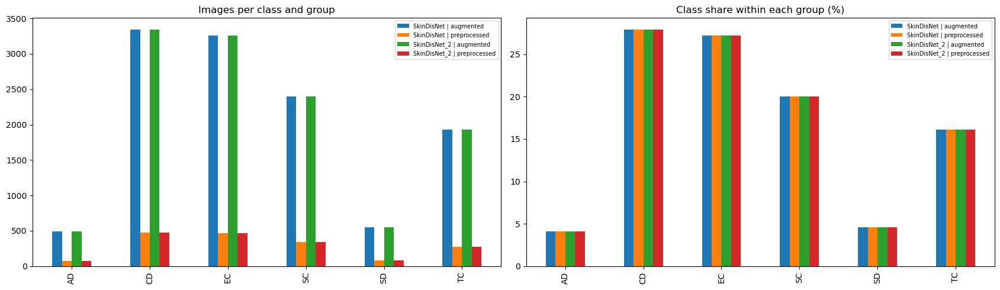


Images per source photo (source name = file name with augmentation/preprocessing suffix removed):


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
SkinDisNet | augmented,1710.0,7.0,0.0,7.0,7.0,7.0,7.0,7.0
SkinDisNet | preprocessed,1710.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
SkinDisNet_2 | augmented,1710.0,7.0,0.0,7.0,7.0,7.0,7.0,7.0
SkinDisNet_2 | preprocessed,1710.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


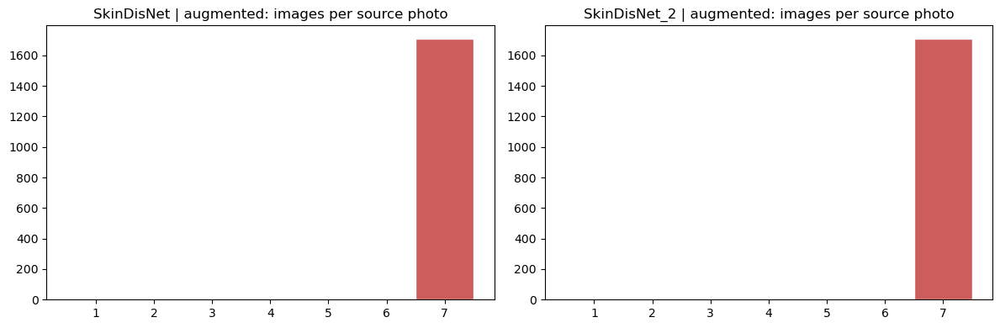

SkinDisNet_2: augmented sources 1710, preprocessed sources 1710, shared 1710, augmented-only 0, preprocessed-only 0
SkinDisNet: augmented sources 1710, preprocessed sources 1710, shared 1710, augmented-only 0, preprocessed-only 0


In [4]:
# ---------- class balance (per group) ----------
ct = pd.crosstab(D.label, D.group)[GROUPS]; ct["total"] = ct.sum(axis=1)
ct.loc["TOTAL"] = ct.sum(); display(ct); ct.to_csv(os.path.join(OUT, "class_by_group.csv"))
for g in GROUPS:
    s = D.loc[D.group == g, "label"].value_counts()
    print(f"{g:32s} images {s.sum():6d} | classes {len(s):2d} | imbalance (largest/smallest): {s.max() / s.min():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
pd.crosstab(D.label, D.group)[GROUPS].plot.bar(ax=ax[0]); ax[0].set_title("Images per class and group"); ax[0].set_xlabel(""); ax[0].legend(fontsize=7)
pct = (pd.crosstab(D.label, D.group, normalize="columns") * 100)[GROUPS]
pct.plot.bar(ax=ax[1]); ax[1].set_title("Class share within each group (%)"); ax[1].set_xlabel(""); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "01_class_balance.png"), dpi=200, bbox_inches="tight"); plt.show()

# ---------- augmentation factor: how many augmented images per source photo ----------
print("\nImages per source photo (source name = file name with augmentation/preprocessing suffix removed):")
spp = D.groupby(["group", "source_l"]).size().rename("n").reset_index()
display(spp.groupby("group").n.describe().round(2))
aug_groups = [g for g in GROUPS if g.endswith("augmented")]
if aug_groups:
    fig, ax = plt.subplots(1, len(aug_groups), figsize=(6 * len(aug_groups), 4), squeeze=False)
    for a, g in zip(ax[0], aug_groups):
        s = spp[spp.group == g].n; a.hist(s, bins=range(1, int(s.max()) + 2), color="indianred", edgecolor="white", align="left"); a.set_title(f"{g}: images per source photo")
    plt.tight_layout(); plt.savefig(os.path.join(FIG, "02_images_per_source.png"), dpi=200, bbox_inches="tight"); plt.show()

# ---------- does every augmented source photo exist in the preprocessed set of the same dataset? ----------
for ds in ROOTS:
    a = set(D[(D.dataset == ds) & (D.stage == "augmented")].source_l); p = set(D[(D.dataset == ds) & (D.stage == "preprocessed")].source_l)
    if a and p:
        print(f"{ds}: augmented sources {len(a)}, preprocessed sources {len(p)}, shared {len(a & p)}, "
              f"augmented-only {len(a - p)}, preprocessed-only {len(p - a)}")

Most common resolutions per group:


,group,width,height,images
0,SkinDisNet | augmented,512,512,11970
1,SkinDisNet | preprocessed,512,512,1710
2,SkinDisNet_2 | augmented,512,512,11970
3,SkinDisNet_2 | preprocessed,512,512,1710


SkinDisNet | augmented           non-square   0.0% | aspect 1.00-1.00 | unique sizes    1 | formats {'JPEG': 11970} | modes {'RGB': 11970} | file KB mean 113
SkinDisNet | preprocessed        non-square   0.0% | aspect 1.00-1.00 | unique sizes    1 | formats {'JPEG': 1710} | modes {'RGB': 1710} | file KB mean 29
SkinDisNet_2 | augmented         non-square   0.0% | aspect 1.00-1.00 | unique sizes    1 | formats {'JPEG': 11970} | modes {'RGB': 11970} | file KB mean 111
SkinDisNet_2 | preprocessed      non-square   0.0% | aspect 1.00-1.00 | unique sizes    1 | formats {'JPEG': 1710} | modes {'RGB': 1710} | file KB mean 28


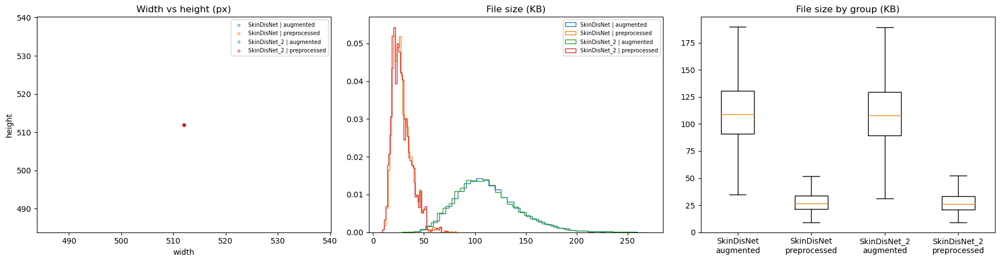

In [5]:
# ---------- image size, aspect ratio, format (per group) ----------
res = D.groupby(["group", "width", "height"]).size().rename("images").reset_index().sort_values(["group", "images"], ascending=[True, False])
print("Most common resolutions per group:"); display(res.groupby("group").head(3))
for g in GROUPS:
    s = D[D.group == g]
    print(f"{g:32s} non-square {(s.width != s.height).mean() * 100:5.1f}% | aspect {s.aspect.min():.2f}-{s.aspect.max():.2f} | "
          f"unique sizes {s.groupby(['width', 'height']).ngroups:4d} | formats {s.format.value_counts().to_dict()} | modes {s['mode'].value_counts().to_dict()} | "
          f"file KB mean {s.file_kb.mean():.0f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for g in GROUPS:
    s = D[D.group == g]; ax[0].scatter(s.width, s.height, s=10, alpha=0.4, label=g)
    ax[1].hist(s.file_kb, bins=40, histtype="step", density=True, label=g)
ax[0].set_title("Width vs height (px)"); ax[0].set_xlabel("width"); ax[0].set_ylabel("height"); ax[0].legend(fontsize=7)
ax[1].set_title("File size (KB)"); ax[1].legend(fontsize=7)
ax[2].boxplot([D.loc[D.group == g, "file_kb"] for g in GROUPS], labels=[g.replace(" | ", "\n") for g in GROUPS], showfliers=False); ax[2].set_title("File size by group (KB)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "03_image_properties.png"), dpi=200, bbox_inches="tight"); plt.show()

Exact duplicate files: 3542 images in 1771 groups | inside one group: 12 | across groups: 1759
which pairs of groups share identical files:


,md5 groups
group,
SkinDisNet | augmented <-> SkinDisNet_2 | augmented,1317
SkinDisNet | preprocessed <-> SkinDisNet_2 | preprocessed,442
SkinDisNet_2 | augmented,9
SkinDisNet | augmented,3


identical files carrying different labels: 5

Near-duplicate pairs (dHash distance <= 4 of 64): 120101
pairs where both images carry different class labels (label conflict): 55987
pairs with different source photo names (hidden duplicates the file names do not reveal): 102986


,pairs,diff_source,label_conflict
pair,,,
SkinDisNet | augmented <-> SkinDisNet_2 | augmented,41830,41830,20437
SkinDisNet_2 | augmented <-> SkinDisNet_2 | augmented,19958,15755,11347
SkinDisNet | augmented <-> SkinDisNet | augmented,17318,13241,9181
SkinDisNet_2 | augmented <-> SkinDisNet_2 | preprocessed,9909,5474,3756
SkinDisNet | preprocessed <-> SkinDisNet_2 | augmented,9195,9195,3492
SkinDisNet | augmented <-> SkinDisNet | preprocessed,9190,4790,3091
SkinDisNet | augmented <-> SkinDisNet_2 | preprocessed,9032,9032,3387
SkinDisNet | preprocessed <-> SkinDisNet_2 | preprocessed,2607,2607,653
SkinDisNet_2 | preprocessed <-> SkinDisNet_2 | preprocessed,554,554,350


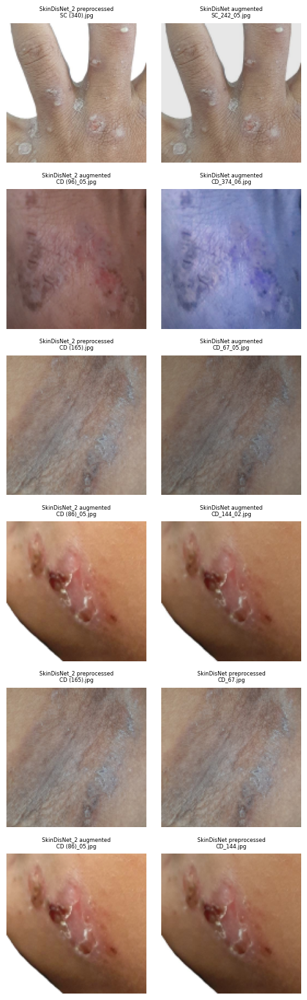

In [6]:
# ---------- duplicates ----------
# 1) exact duplicates (identical bytes)
dup = D[D.duplicated("md5", keep=False)]
within = dup.groupby("md5").group.nunique().eq(1).sum(); across = dup.groupby("md5").group.nunique().gt(1).sum()
print(f"Exact duplicate files: {len(dup)} images in {dup.md5.nunique()} groups | inside one group: {within} | across groups: {across}")
if len(dup):
    print("which pairs of groups share identical files:")
    pairs_g = dup.groupby("md5").group.apply(lambda s: " <-> ".join(sorted(set(s)))).value_counts(); display(pairs_g.to_frame("md5 groups"))
    cl = dup.groupby("md5").label.nunique(); print("identical files carrying different labels:", int((cl > 1).sum()))
    dup.sort_values("md5")[["md5", "group", "Image_id", "label"]].to_csv(os.path.join(OUT, "exact_duplicates.csv"))

# 2) near duplicates with dHash (catches resized / re-encoded / lightly edited copies; flips are NOT caught)
Hh = np.array([int(x) for x in D.dhash], dtype=np.uint64); idx = D.index.to_numpy(); pairs = []; CAP = 300_000
for i in range(len(Hh) - 1):
    x = np.bitwise_xor(Hh[i + 1:], Hh[i])
    dist = np.unpackbits(x.view(np.uint8).reshape(-1, 8), axis=1).sum(1)
    for j in np.where(dist <= 4)[0]: pairs.append((i, i + 1 + j, int(dist[j])))
    if len(pairs) > CAP: print("pair cap reached, stopping early"); break
nd = pd.DataFrame([dict(a=idx[a], b=idx[b], dist=d) for a, b, d in pairs])
print("\nNear-duplicate pairs (dHash distance <= 4 of 64):", len(nd))
if len(nd):
    for s_ in "ab":
        for c in ("group", "label", "source_l", "Image_id"): nd[f"{c}_{s_}"] = D.loc[nd[s_], c].values
    nd["same_group"] = nd.group_a == nd.group_b; nd["same_label"] = nd.label_a == nd.label_b; nd["same_source"] = nd.source_l_a == nd.source_l_b
    print("pairs where both images carry different class labels (label conflict):", int((~nd.same_label).sum()))
    print("pairs with different source photo names (hidden duplicates the file names do not reveal):", int((~nd.same_source).sum()))
    pg = nd.assign(pair=[" <-> ".join(sorted([x, y])) for x, y in zip(nd.group_a, nd.group_b)]).groupby("pair").agg(
        pairs=("dist", "size"), diff_source=("same_source", lambda s: int((~s).sum())), label_conflict=("same_label", lambda s: int((~s).sum())))
    display(pg.sort_values("pairs", ascending=False))
    nd.drop(columns=["a", "b"]).to_csv(os.path.join(OUT, "near_duplicates.csv"), index=False)
    hidden = nd[(~nd.same_source)].sort_values("dist").head(6)
    if len(hidden):
        fig, axes = plt.subplots(len(hidden), 2, figsize=(5, 2.6 * len(hidden))); axes = np.atleast_2d(axes)
        for r_, (_, row) in enumerate(hidden.iterrows()):
            for k, u in enumerate((row.a, row.b)):
                axes[r_, k].imshow(cv2.cvtColor(load_thumb(D.loc[u, "path"]), cv2.COLOR_BGR2RGB)); axes[r_, k].axis("off")
                axes[r_, k].set_title(f"{D.loc[u, 'group'].replace(' | ', ' ')}\n{D.loc[u, 'Image_id'][:22]}", fontsize=6)
        plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_hidden_near_duplicates.png"), dpi=200, bbox_inches="tight"); plt.show()


Leakage-safe groups: 1340 (name links alone: 3420) | files per group: median 16, max 1400
groups present in both dataset folders: 1101 of 1340
largest groups (a very large group would mean chaining; lower LINK_DIST if so): [1400, 1368, 864, 768, 488]


,groups
files per group,
8,238
16,976
24,20
32,65
40,5
48,20
64,4
80,1
88,1


mean_L          contrast            entropy  \
                               mean    std       mean        std    mean   
group                                                                      
SkinDisNet | augmented       144.00  34.14  39.590000  19.610001    6.05   
SkinDisNet | preprocessed    144.89  31.92  37.049999  18.799999    6.07   
SkinDisNet_2 | augmented     144.58  33.77  39.320000  19.600000    6.03   
SkinDisNet_2 | preprocessed  145.58  31.77  36.730000  18.799999    6.04   

                                  sharpness         noise          sat         \
                              std      mean     std  mean   std   mean    std   
group                                                                           
SkinDisNet | augmented       0.64    217.44  313.21  0.99  0.72  56.04  27.12   
SkinDisNet | preprocessed    0.63    229.31  343.58  0.96  0.75  56.71  27.31   
SkinDisNet_2 | augmented     0.64    210.47  295.80  0.97  0.70  55.90  26.62   
SkinDisNet_2 | preprocessed  0.65    219.91  308.96  0.94  0.72  56.54  26.80   

                            dark_pct       bright_pct         
                                mean   std       mean    std  
group                                                         
SkinDisNet | augmented          1.76  4.18      10.68  14.27  
SkinDisNet | preprocessed       0.05  0.37      11.11  14.18  
SkinDisNet_2 | augmented        1.80  4.38      10.48  14.24  
SkinDisNet_2 | preprocessed     0.10  1.26      11.04  14.26

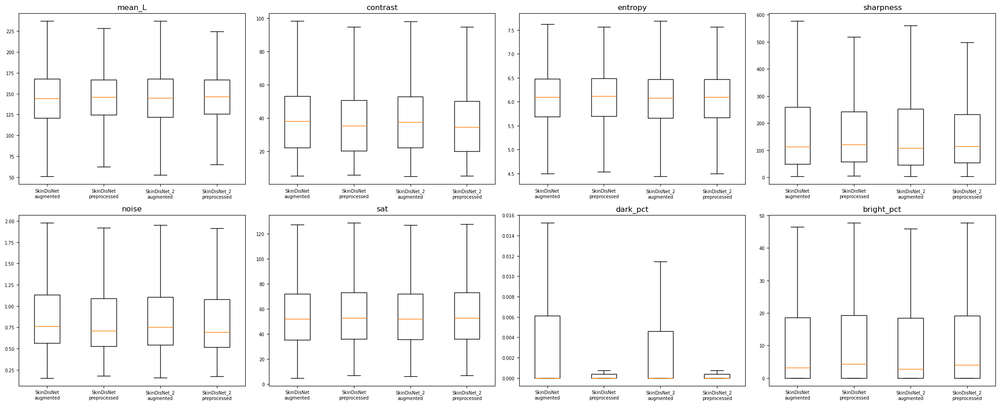

Kruskal-Wallis p-value across classes, per group (p < 0.05: classes differ, so a CNN could shortcut on it):


,mean_L,contrast,entropy,sharpness,noise,sat,dark_pct,bright_pct
SkinDisNet | augmented,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0
SkinDisNet | preprocessed,0.0,0.0,0.0,0.0012,0.0001,0.0014,0.0,0.0
SkinDisNet_2 | augmented,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0
SkinDisNet_2 | preprocessed,0.0,0.0,0.0,0.0006,0.0018,0.0002,0.0,0.0


significant (p < 0.05): {'SkinDisNet | augmented': ['mean_L', 'contrast', 'entropy', 'sharpness', 'noise', 'sat', 'dark_pct', 'bright_pct'], 'SkinDisNet | preprocessed': ['mean_L', 'contrast', 'entropy', 'sharpness', 'noise', 'sat', 'dark_pct', 'bright_pct'], 'SkinDisNet_2 | augmented': ['mean_L', 'contrast', 'entropy', 'sharpness', 'noise', 'sat', 'dark_pct', 'bright_pct'], 'SkinDisNet_2 | preprocessed': ['mean_L', 'contrast', 'entropy', 'sharpness', 'noise', 'sat', 'dark_pct', 'bright_pct']}


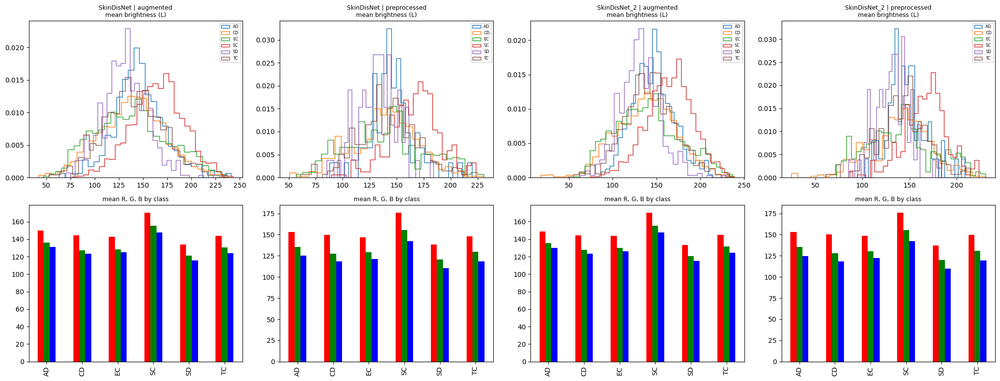

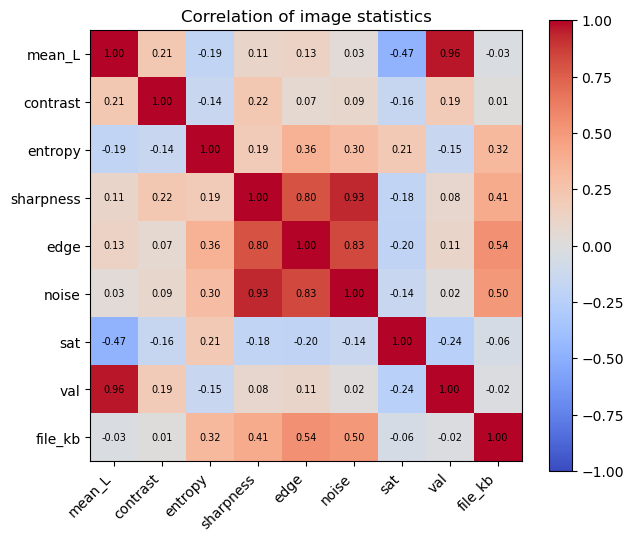

Effect of stage on matched photos (preprocessed minus augmented, mean over shared source photos):


,SkinDisNet_2 (n=1710),SkinDisNet (n=1710)
mean_L,1.00,0.90
contrast,-2.59,-2.54
entropy,0.01,0.02
sharpness,9.43,11.87
noise,-0.02,-0.02
sat,0.65,0.67
dark_pct,-1.71,-1.70
bright_pct,0.56,0.43


In [7]:
# 3) leakage-safe groups: files of the same photo (augmented copies, preprocessed original, and the same photo in the other dataset folder)
LINK_DIST = globals().get("LINK_DIST", 4)
uids = D.index.to_numpy(); pos = {u: i for i, u in enumerate(uids)}; parent = np.arange(len(uids))
def find(x):
    while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra
prep_pos = {(d, sl, lb): pos[u] for u, d, sl, lb in zip(D.index[D.stage == "preprocessed"], D.dataset[D.stage == "preprocessed"], D.source_l[D.stage == "preprocessed"], D.label[D.stage == "preprocessed"])}
for u, d, sl, lb in zip(D.index[D.stage == "augmented"], D.dataset[D.stage == "augmented"], D.source_l[D.stage == "augmented"], D.label[D.stage == "augmented"]):
    p = prep_pos.get((d, sl, lb))
    if p is not None: union(pos[u], p)                                    # name link: augmented copy -> its preprocessed source (same dataset)
n_name = len(set(find(i) for i in range(len(uids))))
if len(nd):
    lk = nd[(nd.dist <= LINK_DIST) & nd.same_label]
    for a_, b_ in zip(lk.a, lk.b): union(pos[a_], pos[b_])                # content link: look-alike images of the same class
D["link_group"] = [find(i) for i in range(len(uids))]
gs = D.groupby("link_group").size()
print(f"\nLeakage-safe groups: {len(gs)} (name links alone: {n_name}) | files per group: median {gs.median():.0f}, max {gs.max()}")
print("groups present in both dataset folders:", int((D.groupby("link_group").dataset.nunique() > 1).sum()), "of", len(gs))
print("largest groups (a very large group would mean chaining; lower LINK_DIST if so):", gs.sort_values(ascending=False).head(5).tolist())
display(gs.value_counts().sort_index().rename("groups").to_frame("groups").rename_axis("files per group").head(25))

# ---------- photometric statistics ----------
from scipy.stats import kruskal
STATS = ["mean_L", "contrast", "entropy", "sharpness", "noise", "sat", "dark_pct", "bright_pct"]
summ = D.groupby("group")[STATS].agg(["mean", "std"]).round(2); display(summ); summ.to_csv(os.path.join(OUT, "photometric_by_group.csv"))

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, s in zip(axes.ravel(), STATS):
    ax.boxplot([D.loc[D.group == g, s] for g in GROUPS], labels=[g.replace(" | ", "\n") for g in GROUPS], showfliers=False); ax.set_title(s); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "05_photometric_by_group.png"), dpi=200, bbox_inches="tight"); plt.show()

# do classes differ on a statistic a CNN could shortcut on? (per group)
kw = {}
for g in GROUPS:
    sub = D[D.group == g]
    if sub.label.nunique() < 2: continue
    kw[g] = {s: kruskal(*[x[s].values for _, x in sub.groupby("label") if len(x) > 1]).pvalue for s in STATS}
if kw:
    KW = pd.DataFrame(kw).T; print("Kruskal-Wallis p-value across classes, per group (p < 0.05: classes differ, so a CNN could shortcut on it):")
    display(KW.round(4)); print("significant (p < 0.05):", {g: [c for c in KW.columns if KW.loc[g, c] < 0.05] for g in KW.index}); KW.to_csv(os.path.join(OUT, "kruskal_by_group.csv"))

# per-class brightness and colour, one panel per group
fig, axes = plt.subplots(2, len(GROUPS), figsize=(5.2 * len(GROUPS), 8), squeeze=False)
for k, g in enumerate(GROUPS):
    sub = D[D.group == g]
    for c in LABELS:
        s = sub.loc[sub.label == c, "mean_L"]
        if len(s) > 1: axes[0, k].hist(s, bins=30, histtype="step", density=True, label=c)
    axes[0, k].set_title(f"{g}\nmean brightness (L)", fontsize=9); axes[0, k].legend(fontsize=6)
    sub.groupby("label")[["R", "G", "B"]].mean().plot.bar(ax=axes[1, k], color=["red", "green", "blue"], legend=False); axes[1, k].set_title("mean R, G, B by class", fontsize=9); axes[1, k].set_xlabel("")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "06_brightness_colour.png"), dpi=200, bbox_inches="tight"); plt.show()

corr = D[["mean_L", "contrast", "entropy", "sharpness", "edge", "noise", "sat", "val", "file_kb"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5)); im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Correlation of image statistics"); plt.tight_layout()
plt.savefig(os.path.join(FIG, "07_correlation.png"), dpi=200, bbox_inches="tight"); plt.show()

# what did preprocessing / augmentation change? compare each group with the other stage of the same dataset (on matched source photos)
print("Effect of stage on matched photos (preprocessed minus augmented, mean over shared source photos):")
eff = []
for ds in ROOTS:
    a = D[(D.dataset == ds) & (D.stage == "augmented")].groupby("source_l")[STATS].mean()
    p = D[(D.dataset == ds) & (D.stage == "preprocessed")].groupby("source_l")[STATS].mean()
    sh = a.index.intersection(p.index)
    if len(sh): eff.append((p.loc[sh] - a.loc[sh]).mean().rename(f"{ds} (n={len(sh)})"))
if eff: display(pd.concat(eff, axis=1).round(2))
else: print("no shared source names between stages (file names differ), skipped")

metadata columns analysed: ['Folder_name', 'Patient_id', 'Age', 'Sex', 'Leision_location'] | rows (one per distinct photo): 1340

===== Folder_name | missing: 120 (9.0%) | unique: 6 =====


label,AD,CD,EC,SC,SD,TC
m_Folder_name,,,,,,
Atopic Dermatitis (AD),42,0,0,0,0,0
Contact Dermatitis (CD),0,347,0,0,0,0
Eczema (EC),0,0,359,0,0,0
Scabies (SC),0,0,0,243,0,0
Seborrheic Dermatitis (SD),0,0,0,0,65,0
Tinea Corporis (TC),0,0,0,0,0,164
missing,8,41,31,8,7,25



===== Patient_id | missing: 120 (9.0%) | unique: 364 =====
high-cardinality column, first values: ['P_339' 'P_332' 'P_336' 'P_341' 'P_344']

===== Age | missing: 120 (9.0%) | unique: 72 =====


,count,mean,std,min,25%,50%,75%,max
Age,1220.0,27.73,20.89,0.06,10.0,23.0,43.0,80.0


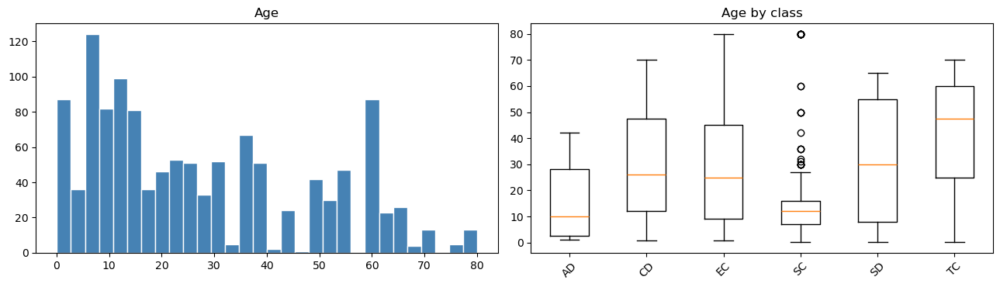


===== Sex | missing: 120 (9.0%) | unique: 2 =====


label,AD,CD,EC,SC,SD,TC
m_Sex,,,,,,
Female,26,181,161,106,41,110
Male,16,166,198,137,24,54
missing,8,41,31,8,7,25



===== Leision_location | missing: 120 (9.0%) | unique: 42 =====
high-cardinality column, first values: ['Forearm' 'Back' 'Head' 'Arm' 'Toe_Nail']

Images beyond 4 robust-SD of their own group+class median on any statistic: 2458 (9.0%)


,outliers
group,
SkinDisNet | augmented,1035
SkinDisNet | preprocessed,179
SkinDisNet_2 | augmented,1057
SkinDisNet_2 | preprocessed,187


,group,Image_id,label,mean_L,contrast,sharpness,noise,file_kb,outlier_score
uid,,,,,,,,,
22285,SkinDisNet | augmented,TC_200_06.jpg,TC,186.26,53.310001,5911.99,10.62,271.59,45.27
20676,SkinDisNet | augmented,TC_175_06.jpg,TC,194.09,52.080002,5399.33,9.17,265.37,41.27
24705,SkinDisNet | augmented,CD_433_06.jpg,CD,148.80,40.180000,4886.42,8.60,243.92,38.63
21852,SkinDisNet | augmented,TC_200_02.jpg,TC,165.55,52.189999,5061.97,9.78,228.97,38.63
3232,SkinDisNet_2 | augmented,CD (71)_06.jpg,CD,148.81,40.180000,4886.22,8.60,243.93,38.05
26818,SkinDisNet | preprocessed,TC_200.jpg,TC,165.57,52.220001,5072.99,9.78,81.57,36.71
20561,SkinDisNet | augmented,TC_175_02.jpg,TC,172.88,50.930000,4530.39,8.20,221.46,34.48
26834,SkinDisNet | preprocessed,TC_175.jpg,TC,172.90,50.959999,4533.66,8.19,77.52,32.71
26885,SkinDisNet | preprocessed,CD_433.jpg,CD,134.60,33.680000,3695.02,7.37,73.17,30.18


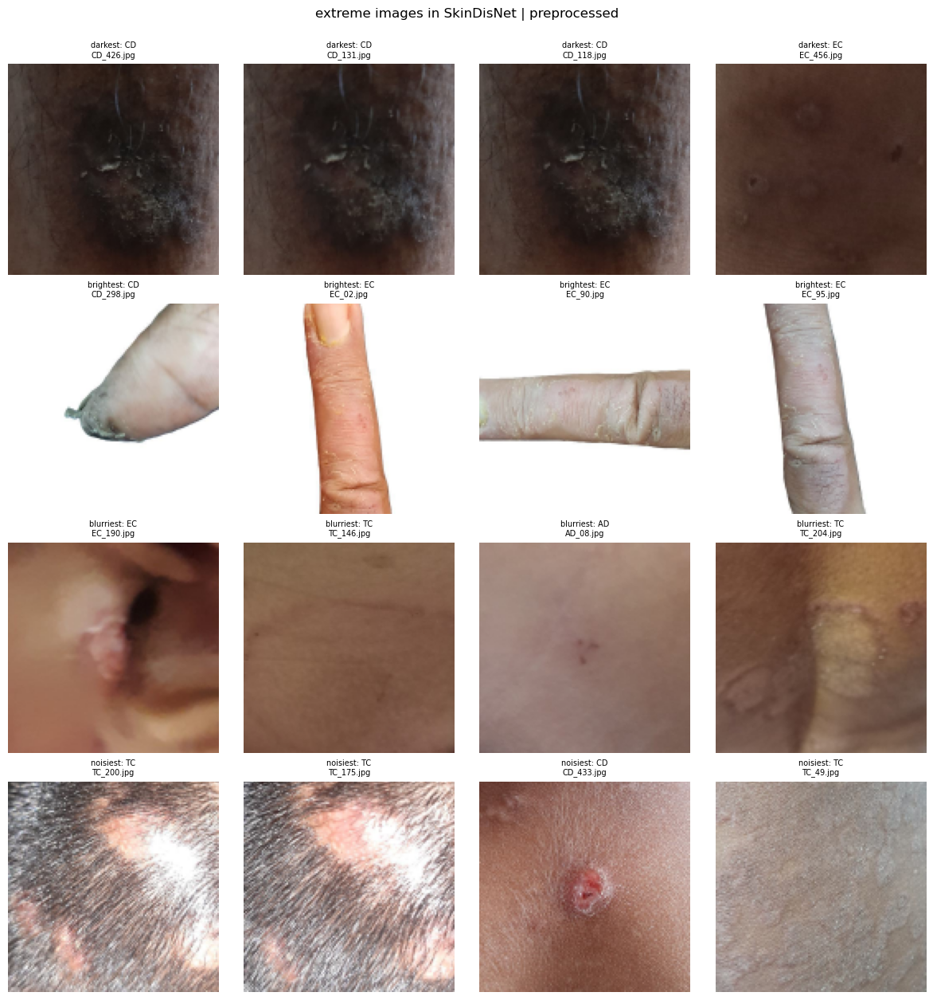

In [8]:
# ---------- metadata columns ----------
mcols = [c for c in D.columns if c.startswith("m_") and c[2:] not in ("meta_dataset", "meta_file", ID_COL or "", LABEL_COL or "") and not c.startswith("m_Unnamed")]
# one row per distinct photo (metadata is repeated on every augmented copy, which would inflate counts)
for c in mcols: D[c] = D[c].fillna(D.groupby("link_group")[c].transform("first"))      # share metadata between copies of the same photo (incl. the other dataset folder)
Dm = D.drop_duplicates("link_group")
print("metadata columns analysed:", [c[2:] for c in mcols], f"| rows (one per distinct photo): {len(Dm)}")
for c in mcols:
    s = Dm[c]
    print(f"\n===== {c[2:]} | missing: {s.isna().sum()} ({s.isna().mean() * 100:.1f}%) | unique: {s.nunique()} =====")
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 12:
        display(s.describe().round(2).to_frame(c[2:]).T)
        fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
        ax[0].hist(s.dropna(), bins=30, color="steelblue", edgecolor="white"); ax[0].set_title(c[2:])
        labs = [k for k in LABELS if Dm.loc[Dm.label == k, c].notna().sum() > 0]
        ax[1].boxplot([Dm.loc[Dm.label == k, c].dropna() for k in labs], labels=labs); ax[1].set_title(f"{c[2:]} by class"); ax[1].tick_params(axis="x", rotation=45)
        plt.tight_layout(); plt.savefig(os.path.join(FIG, f"meta_{re.sub(r'[^A-Za-z0-9]+', '_', c[2:])}.png"), dpi=200, bbox_inches="tight"); plt.show()
    elif s.nunique() <= 25:
        display(pd.crosstab(s.fillna("missing"), Dm.label))
    else:
        print("high-cardinality column, first values:", s.dropna().astype(str).unique()[:5])
if not mcols: print("no extra metadata columns were matched to images (check ID_COL in Cell 2)")

# ---------- outliers (robust z-score inside each group and class) ----------
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median() * 1.4826 + 1e-9
    return (s - med) / mad
OS = ["mean_L", "contrast", "sharpness", "noise", "file_kb"]
Z = pd.DataFrame({s: D.groupby(["group", "label"])[s].transform(robust_z) for s in OS})
D["outlier_score"] = Z.abs().max(axis=1)
flag = D[D.outlier_score > 4].sort_values("outlier_score", ascending=False)
print(f"\nImages beyond 4 robust-SD of their own group+class median on any statistic: {len(flag)} ({len(flag) / len(D) * 100:.1f}%)")
display(flag.groupby("group").size().rename("outliers").to_frame())
display(flag[["group", "Image_id", "label", "mean_L", "contrast", "sharpness", "noise", "file_kb", "outlier_score"]].head(15).round(2))
flag[["group", "Image_id", "label", "outlier_score"]].to_csv(os.path.join(OUT, "outlier_candidates.csv"))

EXG = [g for g in GROUPS if g.endswith("preprocessed")] or GROUPS
Dx = D[D.group == EXG[0]]
groups_ = [("darkest", Dx.nsmallest(4, "mean_L")), ("brightest", Dx.nlargest(4, "mean_L")),
           ("blurriest", Dx.nsmallest(4, "sharpness")), ("noisiest", Dx.nlargest(4, "noise"))]
fig, axes = plt.subplots(4, 4, figsize=(12, 12.5))
for r_, (name, g) in enumerate(groups_):
    for k, (u, row) in enumerate(g.iterrows()):
        a = axes[r_, k]; a.imshow(cv2.cvtColor(load_thumb(row.path), cv2.COLOR_BGR2RGB)); a.axis("off"); a.set_title(f"{name}: {row.label}\n{row.Image_id[:18]}", fontsize=7)
fig.suptitle(f"extreme images in {EXG[0]}", y=1.0); plt.tight_layout()
plt.savefig(os.path.join(FIG, "10_extreme_images.png"), dpi=200, bbox_inches="tight"); plt.show()

In [9]:
# ---------- leakage-safe split plan ----------
# Folds are assigned per LINK GROUP (a photo + all its augmented copies + the same photo in the other dataset folder),
# so no copy of a photo can sit in test while another copy sits in train.
from sklearn.model_selection import StratifiedGroupKFold
D["fold"] = -1
for f, (_, te) in enumerate(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(D, D.label, groups=D.link_group)):
    D.iloc[te, D.columns.get_loc("fold")] = f
print("Images per class in each fold:"); display(pd.crosstab(D.label, D.fold))
print("Images per group in each fold:"); display(pd.crosstab(D.group, D.fold))
print("Link groups shared between folds:", int((D.groupby("link_group").fold.nunique() > 1).sum()), "(must be 0)")
if len(nd):
    cross = nd.assign(fa=D.loc[nd.a, "fold"].values, fb=D.loc[nd.b, "fold"].values); cross = cross[cross.fa != cross.fb]
    print(f"near-duplicate pairs split across folds: same class {int(cross.same_label.sum())} (must be 0) | different class {int((~cross.same_label).sum())} (look-alikes with conflicting labels, see near_duplicates.csv)")
    cross.drop(columns=["a", "b"]).to_csv(os.path.join(OUT, "pairs_across_folds.csv"), index=False)
D[["group", "Image_id", "label", "link_group", "fold"]].to_csv(os.path.join(OUT, "folds_leakage_safe.csv"))

summary = {"images_total": len(D), "groups": len(GROUPS), "classes": D.label.nunique(), "distinct_photos_(link_groups)": D.link_group.nunique(),
           "exact_duplicate_images": int(D.duplicated("md5", keep=False).sum()), "near_duplicate_pairs": len(nd),
           "outlier_candidates": len(flag), "mean_brightness_L": round(D.mean_L.mean(), 1),
           "mean_contrast": round(D.contrast.mean(), 1), "mean_sharpness": round(D.sharpness.mean(), 1)}
for g in GROUPS: summary[f"imbalance | {g}"] = round(D[D.group == g].label.value_counts().pipe(lambda s: s.max() / s.min()), 2)
S = pd.Series(summary, name="value").to_frame(); display(S); S.to_csv(os.path.join(OUT, "eda_summary.csv"))
print("Tables saved in:", os.path.abspath(OUT)); print("Pictures saved in:", os.path.abspath(FIG))

Images per class in each fold:


fold,0,1,2,3,4
label,,,,,
AD,144,336,168,120,352
CD,1176,1288,2672,1280,1216
EC,1080,1168,1448,2328,1432
SC,888,1608,1352,760,880
SD,192,304,352,232,184
TC,496,592,1976,736,600


Images per group in each fold:


fold,0,1,2,3,4
group,,,,,
SkinDisNet | augmented,1750,2296,3500,2338,2086
SkinDisNet | preprocessed,250,328,500,334,298
SkinDisNet_2 | augmented,1729,2338,3472,2436,1995
SkinDisNet_2 | preprocessed,247,334,496,348,285


Link groups shared between folds: 0 (must be 0)
near-duplicate pairs split across folds: same class 0 (must be 0) | different class 50088 (look-alikes with conflicting labels, see near_duplicates.csv)


,value
images_total,27360.000000
groups,4.000000
classes,6.000000
distinct_photos_(link_groups),1340.000000
exact_duplicate_images,3542.000000
near_duplicate_pairs,120101.000000
outlier_candidates,2458.000000
mean_brightness_L,144.400000
mean_contrast,39.099998
mean_sharpness,215.300000


Tables saved in: /Users/macbook/Desktop/projects/SkinDisNet - EDA/eda_skindisnet
Pictures saved in: /Users/macbook/Desktop/projects/SkinDisNet - EDA/eda_skindisnet/figures


# Part B: preprocessing comparison
Same methods and decision rules as the scabies notebook. It runs on **one chosen group** (default: the first `preprocessed` group) so results are not mixed with augmented copies.
Change `PARTB_GROUP` to run it on another group, and run it again for the second dataset to answer the question the scabies notebook left open: *does the same method win on both datasets?*

Part B group: SkinDisNet | preprocessed
loaded: 1710 | unreadable: 0


,images,photos
label,,
AD,70,1
CD,477,1
EC,466,1
SC,343,1
SD,79,1
TC,275,1


demo photos: ['AD | AD_66.jpg', 'CD | CD_348.jpg', 'EC | EC_256.jpg', 'SC | SC_65.jpg']


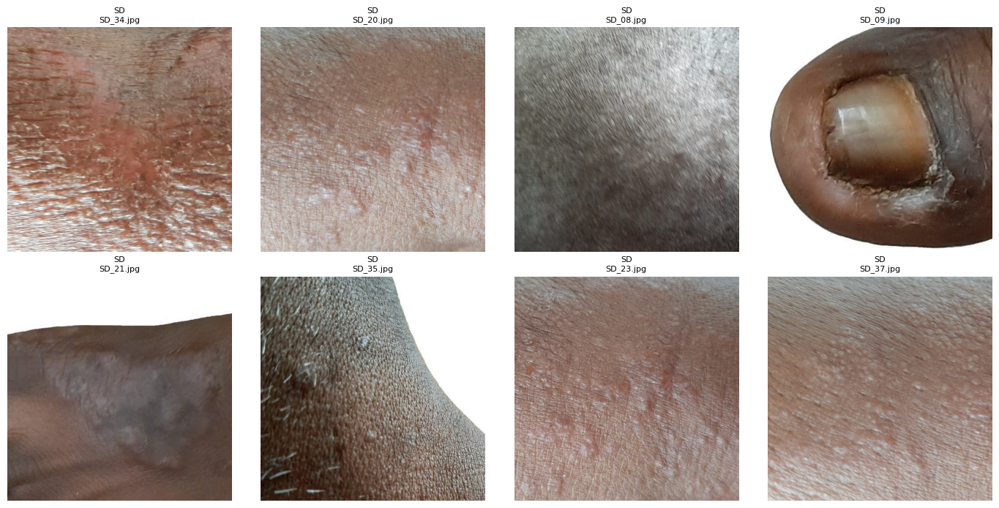

In [10]:
# ---------- choose the group and load images ----------
PARTB_GROUP = [g for g in GROUPS if g.endswith("preprocessed")][0] if any(g.endswith("preprocessed") for g in GROUPS) else GROUPS[0]
# PARTB_GROUP = "SkinDisNet | preprocessed"      # uncomment to switch dataset
PARTB_CLASSES = None        # e.g. ["Scabies"] to restrict to some classes; None = all classes in the group
print("Part B group:", PARTB_GROUP)

def resize_keep_aspect(img, size=SIZE, mode=RESIZE_MODE):
    h, w = img.shape[:2]; S = size[0]
    if mode == "stretch": return cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    if mode == "crop":
        s = S / min(h, w); r = cv2.resize(img, (max(S, round(w * s)), max(S, round(h * s))), interpolation=cv2.INTER_AREA)
        y0, x0 = (r.shape[0] - S) // 2, (r.shape[1] - S) // 2; return r[y0:y0 + S, x0:x0 + S]
    s = S / max(h, w); r = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    top, left = (S - r.shape[0]) // 2, (S - r.shape[1]) // 2
    return cv2.copyMakeBorder(r, top, S - r.shape[0] - top, left, S - r.shape[1] - left, cv2.BORDER_REFLECT_101)

sel_meta = D[D.group == PARTB_GROUP]
if PARTB_CLASSES: sel_meta = sel_meta[sel_meta.label.isin(PARTB_CLASSES)]
if PARTB_MAX and len(sel_meta) > PARTB_MAX: sel_meta = sel_meta.sample(PARTB_MAX, random_state=SEED)
selected, bad_b = {}, []
for u, r in sel_meta.iterrows():
    img = cv2.imread(r.path)
    if img is None: bad_b.append(r.Image_id); continue
    selected[u] = resize_keep_aspect(img)
sel_meta = sel_meta.loc[list(selected)]
print("loaded:", len(selected), "| unreadable:", len(bad_b))
display(sel_meta.groupby("label").agg(images=("Image_id", "count"), photos=("patient", "nunique")))

# 4 demo photos: one from each of the first 4 classes (or random if fewer classes)
labs_b = sorted(sel_meta.label.unique()); PHOTOS = []
for c in labs_b[:4]: PHOTOS.append(int(rng.choice(sel_meta.index[sel_meta.label == c])))
while len(PHOTOS) < 4: PHOTOS.append(int(rng.choice(sel_meta.index)))
PHOTO_NAME = {u: f"{sel_meta.loc[u, 'label'][:12]} | {sel_meta.loc[u, 'Image_id'][:14]}" for u in PHOTOS}
print("demo photos:", list(PHOTO_NAME.values()))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, u in zip(axes.ravel(), list(selected)[:8]):
    ax.imshow(cv2.cvtColor(selected[u], cv2.COLOR_BGR2RGB)); ax.set_title(f"{sel_meta.loc[u, 'label'][:14]}\n{sel_meta.loc[u, 'Image_id'][:16]}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "11_partB_preview.png"), dpi=200, bbox_inches="tight"); plt.show()

In [11]:
# ---------- method definitions ----------
def stretch(L):
    lo, hi = np.percentile(L, (2, 98)); return np.clip((L.astype(np.float32) - lo) / max(hi - lo, 1) * 255, 0, 255).astype(np.uint8)
def log_tf(L):
    c = 255 / np.log(256); return np.clip(c * np.log1p(L.astype(np.float32)), 0, 255).astype(np.uint8)
def gamma(L, g): return np.clip(255 * (L.astype(np.float32) / 255) ** g, 0, 255).astype(np.uint8)
def hist_eq(L): return cv2.equalizeHist(L)
def mean3(L): return cv2.blur(L, (3, 3))
def median3(L): return cv2.medianBlur(L, 3)
def laplacian_sharp(L):
    f = L.astype(np.float32); return np.clip(f - 0.5 * cv2.Laplacian(f, cv2.CV_32F), 0, 255).astype(np.uint8)
def unsharp(L, sigma=1.0, k=1.0):
    f = L.astype(np.float32); b = cv2.GaussianBlur(f, (0, 0), sigma); return np.clip(f + k * (f - b), 0, 255).astype(np.uint8)
def _edge(L, kx, ky):
    f = L.astype(np.float32); return np.clip(np.hypot(cv2.filter2D(f, -1, kx), cv2.filter2D(f, -1, ky)), 0, 255).astype(np.uint8)
def sobel(L):   return _edge(L, np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32), np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32))
def prewitt(L): return _edge(L, np.array([[-1, 0, 1]] * 3, np.float32), np.array([[-1] * 3, [0] * 3, [1] * 3], np.float32))
def roberts(L): return _edge(L, np.array([[1, 0], [0, -1]], np.float32), np.array([[0, 1], [-1, 0]], np.float32))

L_FUNCS = {"stretch": stretch, "log": log_tf, "gamma_0.7": lambda L: gamma(L, 0.7), "gamma_1.5": lambda L: gamma(L, 1.5),
           "hist_eq": hist_eq, "mean_3x3": mean3, "median_3x3": median3, "laplacian": laplacian_sharp,
           "unsharp": lambda L: unsharp(L, 1.0, 1.0), "highboost_k2": lambda L: unsharp(L, 1.0, 2.0)}
_EDGE_FUNCS = {"sobel": sobel, "prewitt": prewitt, "roberts": roberts}
def _on_L(img, fn):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB); lab[:, :, 0] = fn(lab[:, :, 0]); return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)
METHODS = {"original": lambda im: im, "negative": lambda im: 255 - im}
METHODS.update({m: (lambda im, fn=fn: _on_L(im, fn)) for m, fn in L_FUNCS.items()})
METHODS.update({m: (lambda im, fn=fn: cv2.cvtColor(fn(get_L(im)), cv2.COLOR_GRAY2BGR)) for m, fn in _EDGE_FUNCS.items()})
print("methods ready:", list(METHODS))

methods ready: ['original', 'negative', 'stretch', 'log', 'gamma_0.7', 'gamma_1.5', 'hist_eq', 'mean_3x3', 'median_3x3', 'laplacian', 'unsharp', 'highboost_k2', 'sobel', 'prewitt', 'roberts']


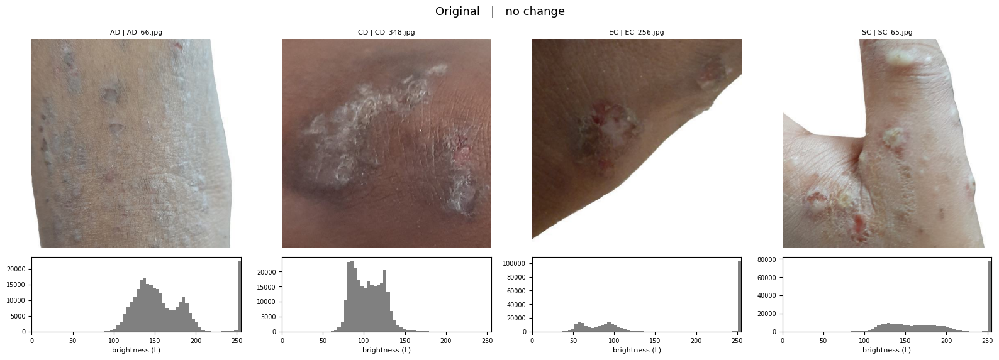

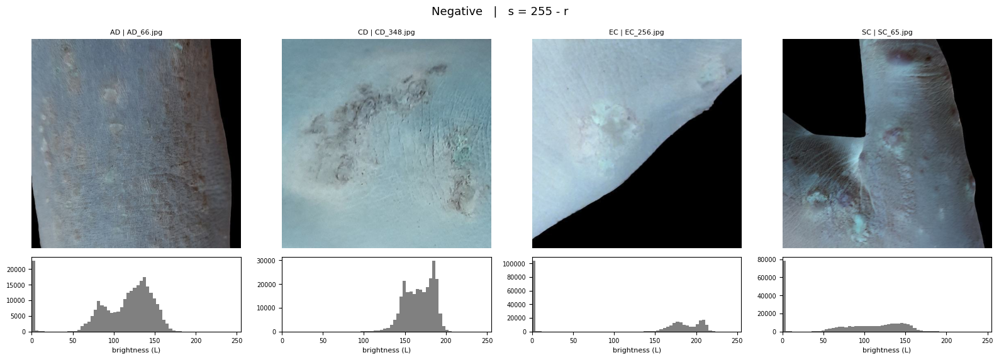

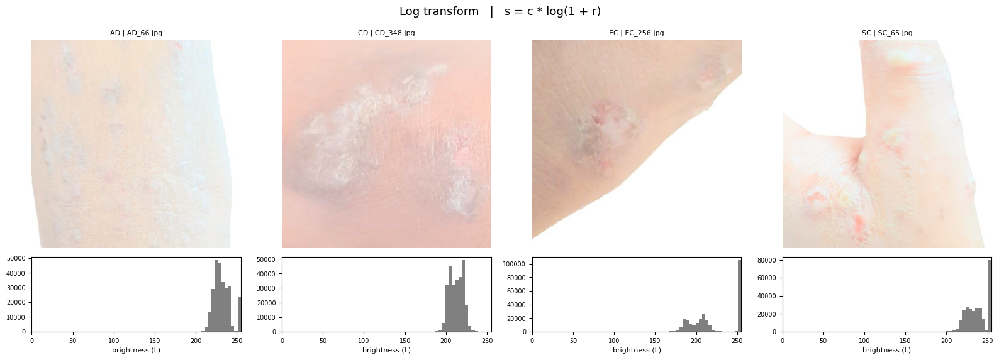

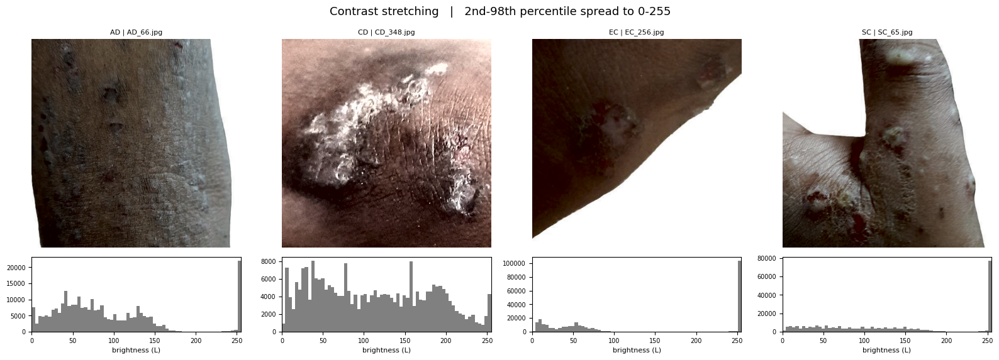

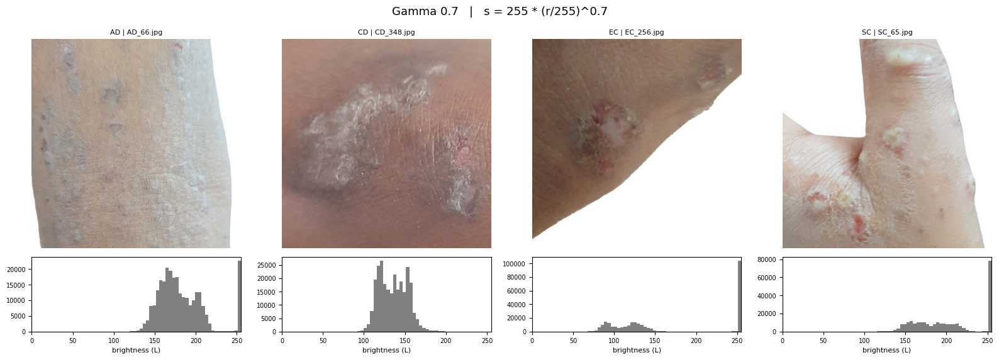

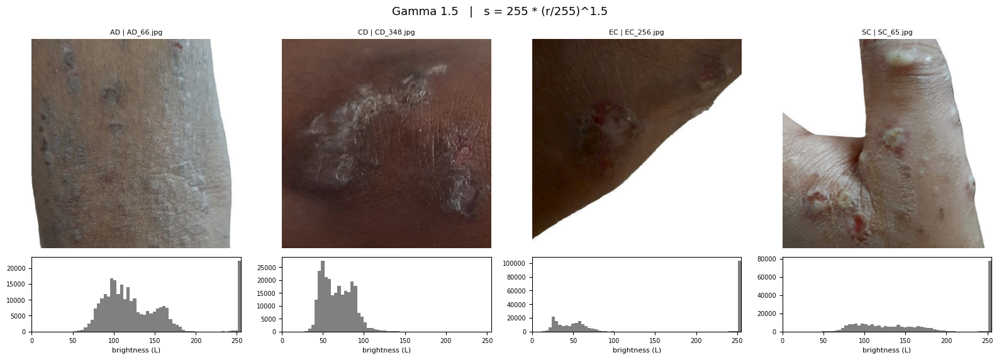

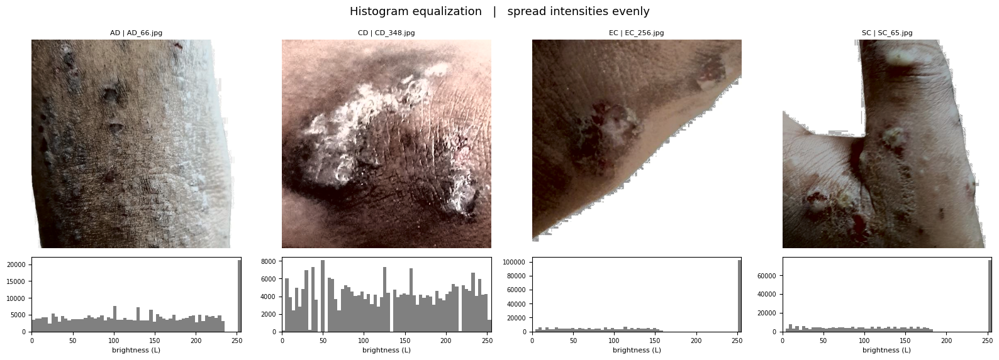

photo                   AD | AD_66.jpg  CD | CD_348.jpg  EC | EC_256.jpg  \
method                                                                     
Original                          37.5             18.9             86.9   
Negative                          42.2             17.5             93.4   
Log transform                     10.0              8.3             28.2   
Contrast stretching               65.7             68.8            107.8   
Gamma 0.7                         29.4             17.1             71.5   
Gamma 1.5                         47.6             18.4            103.3   
Histogram equalization            74.6             73.0             92.5   

photo                   SC | SC_65.jpg  
method                                  
Original                          51.8  
Negative                          59.3  
Log transform                     13.2  
Contrast stretching               89.8  
Gamma 0.7                         40.1  
Gamma 1.5                   

In [12]:
# ---------- visual comparison: intensity transformations ----------
SHOW = ["original", "negative", "log", "stretch", "gamma_0.7", "gamma_1.5", "hist_eq"]
TITLES = {"original": "Original", "negative": "Negative", "log": "Log transform", "stretch": "Contrast stretching",
          "gamma_0.7": "Gamma 0.7", "gamma_1.5": "Gamma 1.5", "hist_eq": "Histogram equalization"}
FORMULAS = {"original": "no change", "negative": "s = 255 - r", "log": "s = c * log(1 + r)", "stretch": "2nd-98th percentile spread to 0-255",
            "gamma_0.7": "s = 255 * (r/255)^0.7", "gamma_1.5": "s = 255 * (r/255)^1.5", "hist_eq": "spread intensities evenly"}
rows = []
for m in SHOW:
    outs = [METHODS[m](selected[u]) for u in PHOTOS]
    fig, axes = plt.subplots(2, 4, figsize=(16, 5.8), gridspec_kw={"height_ratios": [4, 1.3]}); fig.suptitle(f"{TITLES[m]}   |   {FORMULAS[m]}", fontsize=13)
    for j, (u, out) in enumerate(zip(PHOTOS, outs)):
        axes[0, j].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); axes[0, j].set_title(PHOTO_NAME[u], fontsize=8); axes[0, j].axis("off")
        L = get_L(out); axes[1, j].hist(L.ravel(), bins=64, range=(0, 255), color="gray"); axes[1, j].set_xlim(0, 255); axes[1, j].set_xlabel("brightness (L)", fontsize=8); axes[1, j].tick_params(labelsize=7)
        rows.append({"method": TITLES[m], "photo": PHOTO_NAME[u], "std_L": L.std()})
    plt.tight_layout(); plt.savefig(os.path.join(FIG, f"intensity_{m}.png"), dpi=200, bbox_inches="tight"); plt.show()
print(pd.DataFrame(rows).pivot(index="method", columns="photo", values="std_L").loc[[TITLES[m] for m in SHOW]].round(1))

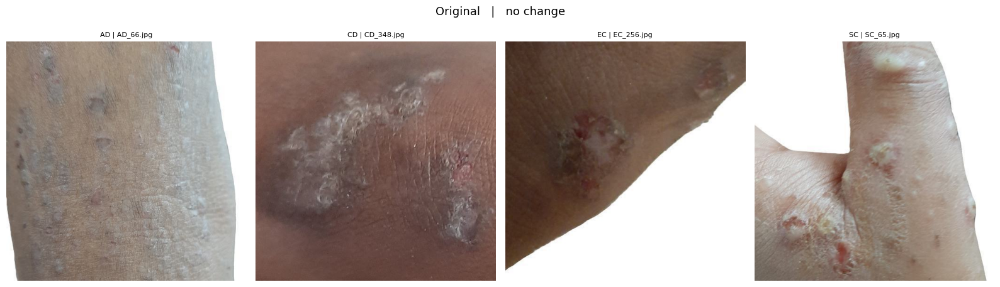

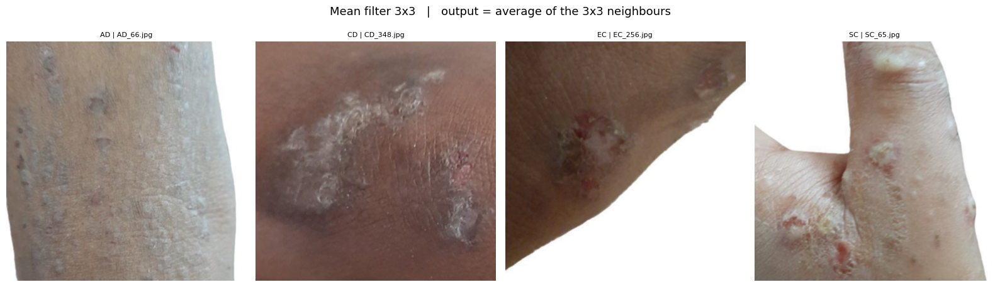

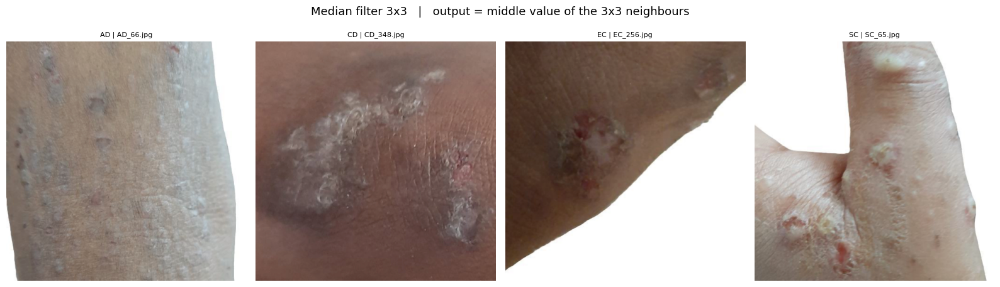

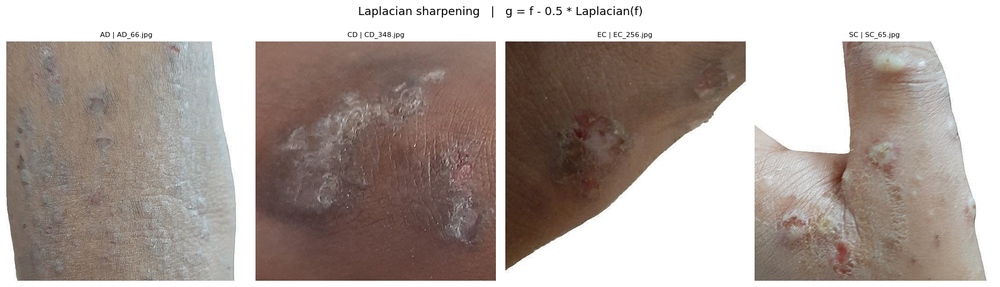

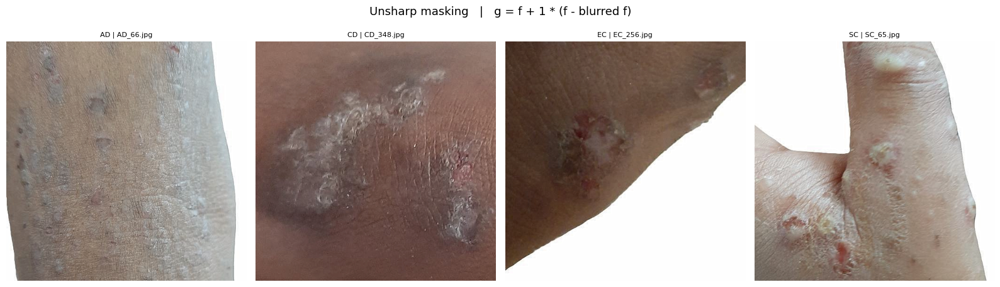

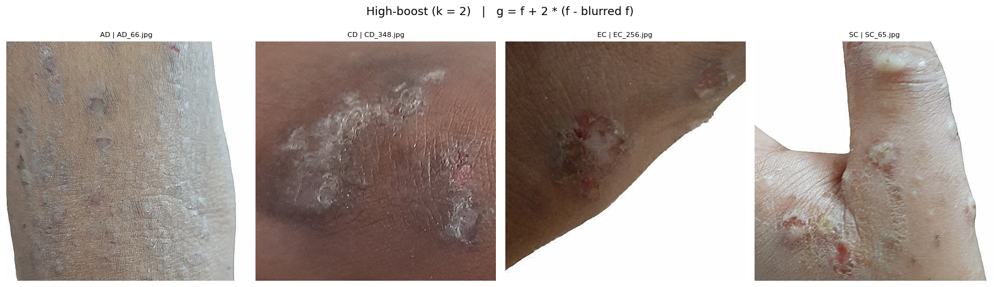

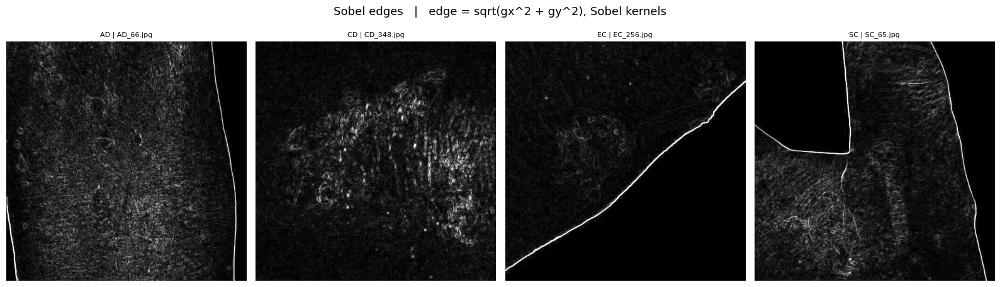

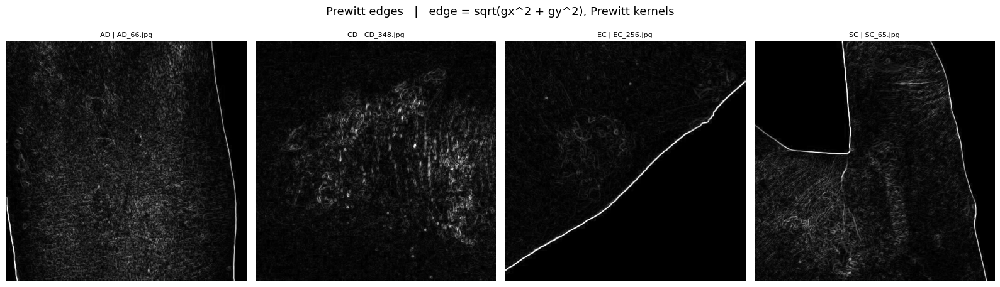

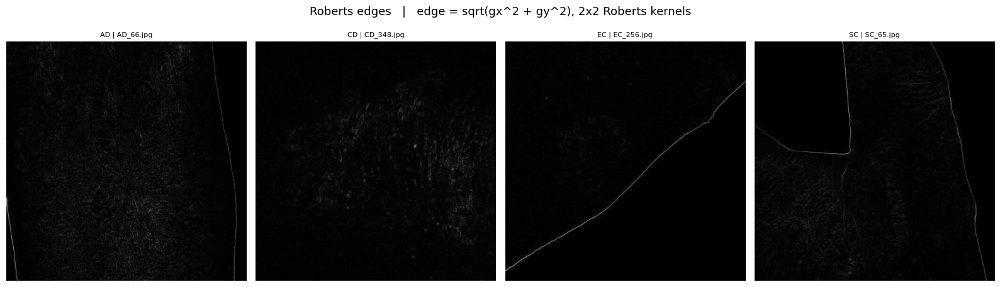

Fine-detail score (Laplacian variance): smoothing should drop, sharpening should rise
photo         AD | AD_66.jpg  CD | CD_348.jpg  EC | EC_256.jpg  SC | SC_65.jpg
method                                                                        
original               242.2             72.6             44.7            78.7
mean_3x3                19.7             12.2              7.5            12.4
median_3x3              58.2             31.6             31.3            43.7
laplacian             1989.9            502.3            300.6           508.7
unsharp                829.8            232.7            131.5           237.3
highboost_k2          1759.7            481.6            249.7           472.4

Mean edge-map brightness (stronger edges = higher)
photo    AD | AD_66.jpg  CD | CD_348.jpg  EC | EC_256.jpg  SC | SC_65.jpg
method                                                                   
prewitt            22.3             15.0              6.4            14.2
roberts 

In [13]:
# ---------- visual comparison: smoothing, sharpening, edge detection ----------
SHOW = ["original", "mean_3x3", "median_3x3", "laplacian", "unsharp", "highboost_k2", "sobel", "prewitt", "roberts"]
TITLES = {"original": "Original", "mean_3x3": "Mean filter 3x3", "median_3x3": "Median filter 3x3", "laplacian": "Laplacian sharpening",
          "unsharp": "Unsharp masking", "highboost_k2": "High-boost (k = 2)", "sobel": "Sobel edges", "prewitt": "Prewitt edges", "roberts": "Roberts edges"}
RULES = {"original": "no change", "mean_3x3": "output = average of the 3x3 neighbours", "median_3x3": "output = middle value of the 3x3 neighbours",
         "laplacian": "g = f - 0.5 * Laplacian(f)", "unsharp": "g = f + 1 * (f - blurred f)", "highboost_k2": "g = f + 2 * (f - blurred f)",
         "sobel": "edge = sqrt(gx^2 + gy^2), Sobel kernels", "prewitt": "edge = sqrt(gx^2 + gy^2), Prewitt kernels", "roberts": "edge = sqrt(gx^2 + gy^2), 2x2 Roberts kernels"}
rows = []
for m in SHOW:
    outs = [METHODS[m](selected[u]) for u in PHOTOS]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.8)); fig.suptitle(f"{TITLES[m]}   |   {RULES[m]}", fontsize=13)
    for ax, u, out in zip(axes, PHOTOS, outs):
        ax.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); ax.set_title(PHOTO_NAME[u], fontsize=8); ax.axis("off")
        L = get_L(out); rows.append({"method": m, "photo": PHOTO_NAME[u], "lap_var": cv2.Laplacian(L, cv2.CV_64F).var(), "mean_L": L.mean()})
    plt.tight_layout(); plt.savefig(os.path.join(FIG, f"spatial_{m}.png"), dpi=200, bbox_inches="tight"); plt.show()
st = pd.DataFrame(rows); enh = [m for m in SHOW if m not in ("sobel", "prewitt", "roberts")]
print("Fine-detail score (Laplacian variance): smoothing should drop, sharpening should rise")
print(st[st.method.isin(enh)].pivot(index="method", columns="photo", values="lap_var").loc[enh].round(1))
print("\nMean edge-map brightness (stronger edges = higher)")
print(st[st.method.isin(list(_EDGE_FUNCS))].pivot(index="method", columns="photo", values="mean_L").round(1))

In [14]:
# ---------- every method on every image (ratio = method / original, same image) ----------
import time
ids = list(selected); recs = []
for n, u in enumerate(ids):
    L = get_L(selected[u]); base = metrics(L)
    for m, fn in L_FUNCS.items():
        t = time.perf_counter(); out = fn(L); ms = (time.perf_counter() - t) * 1000; r = metrics(out)
        recs.append(dict(image=u, patient=sel_meta.loc[u, "patient"], label=sel_meta.loc[u, "label"], method=m,
            contrast_r=r["contrast"] / base["contrast"], entropy_r=r["entropy"] / base["entropy"], edge_r=r["edge"] / base["edge"],
            noise_r=r["noise"] / base["noise"], dnr_r=(r["edge"] / r["noise"]) / (base["edge"] / base["noise"]), time_ms=ms))
    if (n + 1) % 200 == 0: print("processed", n + 1, "of", len(ids))
single = pd.DataFrame(recs); single.to_csv(os.path.join(OUT, f"single_metrics_{re.sub(r'[^A-Za-z0-9]+', '_', PARTB_GROUP)}.csv"), index=False)
METRIC_COLS = ["contrast_r", "entropy_r", "edge_r", "noise_r", "dnr_r", "time_ms"]
pm = single.groupby(["patient", "method"])[METRIC_COLS].mean().reset_index()      # average per patient / source photo so large photo-sets do not dominate
print("images:", single.image.nunique(), "| patients / source photos:", pm.patient.nunique())
all_winners = {}

def run_group(name, methods, ok, score, rule_text, data=None):
    sub = (pm if data is None else data); sub = sub[sub.method.isin(methods)]
    T_ = sub.groupby("method")[METRIC_COLS].mean().loc[methods]; T_["pass"] = ok(T_)
    T_["patients_pass_%"] = (sub.assign(p=ok(sub)).groupby("method")["p"].mean() * 100).loc[methods].round(1)
    T_["rank"] = T_[score].where(T_["pass"]).rank(ascending=False, method="min").map(lambda v: "-" if pd.isna(v) else int(v))
    print(f"\n===== {name.upper()} ({single.image.nunique()} images, {pm.patient.nunique()} patients) =====\nRule:", rule_text)
    display(T_.round(3))
    print(f"Spread of {score} across patients:"); display(sub.groupby("method")[score].agg(median="median", std="std", min="min", max="max").loc[methods].round(3))
    ranked = T_[T_["pass"]].sort_values(score, ascending=False)
    if len(ranked):
        print("Ranking (best first):", " > ".join(f"{m} ({v:.3f})" for m, v in ranked[score].items())); print("Winner:", ranked.index[0]); all_winners[name] = ranked.index[0]
    else: print("No method passed the rule."); all_winners[name] = None
    print("Failed the rule:", list(T_.index[~T_["pass"]]) or "none")

run_group("intensity", ["stretch", "log", "gamma_0.7", "gamma_1.5", "hist_eq"], ok=lambda T_: (T_.noise_r <= 1.5) & (T_.entropy_r >= 0.95),
          score="contrast_r", rule_text="noise ratio <= 1.5 and entropy ratio >= 0.95; ranked by contrast gain")

processed 200 of 1710
processed 400 of 1710
processed 600 of 1710
processed 800 of 1710
processed 1000 of 1710
processed 1200 of 1710
processed 1400 of 1710
processed 1600 of 1710
images: 1710 | patients / source photos: 1

===== INTENSITY (1710 images, 1 patients) =====
Rule: noise ratio <= 1.5 and entropy ratio >= 0.95; ranked by contrast gain


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,time_ms,pass,patients_pass_%,rank
method,,,,,,,,,
stretch,2.362,0.979,2.335,2.440,0.958,1.220,False,0.0,-
log,0.334,0.782,0.374,0.526,0.719,0.750,False,0.0,-
gamma_0.7,0.830,0.960,0.860,0.926,0.930,0.821,True,100.0,2
gamma_1.5,1.163,0.989,1.090,1.132,0.963,0.822,True,100.0,1
hist_eq,2.759,0.982,3.284,3.760,0.868,0.264,False,0.0,-


Spread of contrast_r across patients:


,median,std,min,max
method,,,,
stretch,2.362,NaN,2.362,2.362
log,0.334,NaN,0.334,0.334
gamma_0.7,0.830,NaN,0.830,0.830
gamma_1.5,1.163,NaN,1.163,1.163
hist_eq,2.759,NaN,2.759,2.759


Ranking (best first): gamma_1.5 (1.163) > gamma_0.7 (0.830)
Winner: gamma_1.5
Failed the rule: ['stretch', 'log', 'hist_eq']


In [15]:
run_group("smoothing", ["mean_3x3", "median_3x3"], ok=lambda T_: T_.edge_r >= 0.7, score="dnr_r",
          rule_text="edge ratio >= 0.7; ranked by detail-to-noise (DNR) gain")


===== SMOOTHING (1710 images, 1 patients) =====
Rule: edge ratio >= 0.7; ranked by detail-to-noise (DNR) gain


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,time_ms,pass,patients_pass_%,rank
method,,,,,,,,,
mean_3x3,0.975,0.995,0.714,0.411,1.956,0.109,True,100.0,1
median_3x3,0.981,0.992,0.749,0.882,0.865,0.117,True,100.0,2


Spread of dnr_r across patients:


,median,std,min,max
method,,,,
mean_3x3,1.956,NaN,1.956,1.956
median_3x3,0.865,NaN,0.865,0.865


Ranking (best first): mean_3x3 (1.956) > median_3x3 (0.865)
Winner: mean_3x3
Failed the rule: none


In [16]:
run_group("sharpening", ["laplacian", "unsharp", "highboost_k2"], ok=lambda T_: T_.noise_r <= 1.5, score="edge_r",
          rule_text="noise ratio <= 1.5; ranked by edge ratio")
print(f"\n===== WINNERS on {PARTB_GROUP} ({len(selected)} images) =====")
for g in ["smoothing", "intensity", "sharpening"]: print(f"{g:11s}: {all_winners.get(g)}")
parts = [all_winners[g] for g in ["smoothing", "intensity", "sharpening"] if all_winners.get(g)]
print("Combination order (smoothing > intensity > sharpening):", " > ".join(parts))


===== SHARPENING (1710 images, 1 patients) =====
Rule: noise ratio <= 1.5; ranked by edge ratio


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,time_ms,pass,patients_pass_%,rank
method,,,,,,,,,
laplacian,1.080,1.021,1.627,3.780,0.433,0.327,False,0.0,-
unsharp,1.045,1.021,1.422,2.012,0.708,0.449,False,0.0,-
highboost_k2,1.101,1.035,1.857,2.927,0.635,0.448,False,0.0,-


Spread of edge_r across patients:


,median,std,min,max
method,,,,
laplacian,1.627,NaN,1.627,1.627
unsharp,1.422,NaN,1.422,1.422
highboost_k2,1.857,NaN,1.857,1.857


No method passed the rule.
Failed the rule: ['laplacian', 'unsharp', 'highboost_k2']

===== WINNERS on SkinDisNet | preprocessed (1710 images) =====
smoothing  : mean_3x3
intensity  : gamma_1.5
sharpening : None
Combination order (smoothing > intensity > sharpening): mean_3x3 > gamma_1.5


In [17]:
# ---------- winners per class (does one class prefer a different method?) ----------
for g, ms in {"intensity": ["stretch", "log", "gamma_0.7", "gamma_1.5", "hist_eq"], "smoothing": ["mean_3x3", "median_3x3"], "sharpening": ["laplacian", "unsharp", "highboost_k2"]}.items():
    sc = {"intensity": "contrast_r", "smoothing": "dnr_r", "sharpening": "edge_r"}[g]
    tab = single[single.method.isin(ms)].groupby(["label", "method"])[sc].mean().unstack()[ms].round(3)
    tab["best"] = tab.idxmax(axis=1); print(f"\n{g} ({sc}, highest wins; rule filtering is not applied here, see the group tables above):"); display(tab)


intensity (contrast_r, highest wins; rule filtering is not applied here, see the group tables above):


method,stretch,log,gamma_0.7,gamma_1.5,hist_eq,best
label,,,,,,
AD,2.432,0.315,0.820,1.177,2.805,hist_eq
CD,2.241,0.343,0.835,1.155,2.650,hist_eq
EC,2.428,0.356,0.845,1.133,2.860,hist_eq
SC,1.876,0.282,0.793,1.250,2.139,hist_eq
SD,2.882,0.354,0.850,1.104,3.358,hist_eq
TC,2.900,0.342,0.839,1.134,3.367,hist_eq



smoothing (dnr_r, highest wins; rule filtering is not applied here, see the group tables above):


method,mean_3x3,median_3x3,best
label,,,
AD,1.655,0.825,mean_3x3
CD,2.031,0.876,mean_3x3
EC,1.983,0.853,mean_3x3
SC,1.899,0.866,mean_3x3
SD,1.995,0.865,mean_3x3
TC,1.916,0.875,mean_3x3



sharpening (edge_r, highest wins; rule filtering is not applied here, see the group tables above):


method,laplacian,unsharp,highboost_k2,best
label,,,,
AD,1.598,1.409,1.829,highboost_k2
CD,1.642,1.430,1.871,highboost_k2
EC,1.607,1.410,1.833,highboost_k2
SC,1.613,1.415,1.841,highboost_k2
SD,1.644,1.436,1.884,highboost_k2
TC,1.655,1.438,1.888,highboost_k2


## Extra 1: does the combination order smoothing > intensity > sharpening actually win?
Applies every order of the three group winners (and each winner alone) to all selected images, with the rule noise ratio <= 1.5 and entropy ratio >= 0.95, ranked by DNR gain.

In [18]:
import itertools
FORCE_CHAIN = None   # e.g. ["median_3x3", "gamma_1.5", "unsharp"] to test orders even when a group has no winner (say so in the report)
GROUPS3 = ["smoothing", "intensity", "sharpening"]
chain = FORCE_CHAIN or [all_winners[g] for g in GROUPS3 if all_winners.get(g)]
print("methods tested:", chain)
if len(chain) < 2:
    print("Order test skipped: needs at least 2 methods. Groups without a winner:", [g for g in GROUPS3 if not all_winners.get(g)])
else:
    def apply_chain(L, names):
        for n in names: L = L_FUNCS[n](L)
        return L
    cands = list(itertools.permutations(chain)) + [(m,) for m in chain]; recs = []
    for u in sel_meta.index:
        L = get_L(selected[u]); base = metrics(L)
        for o in cands:
            r = metrics(apply_chain(L, o))
            recs.append(dict(patient=sel_meta.loc[u, "patient"], order=" > ".join(o), contrast_r=r["contrast"] / base["contrast"], entropy_r=r["entropy"] / base["entropy"],
                edge_r=r["edge"] / base["edge"], noise_r=r["noise"] / base["noise"], dnr_r=(r["edge"] / r["noise"]) / (base["edge"] / base["noise"])))
    co = pd.DataFrame(recs).groupby(["patient", "order"]).mean().reset_index()
    CT = co.groupby("order")[["contrast_r", "entropy_r", "edge_r", "noise_r", "dnr_r"]].mean()
    CT["pass"] = (CT.noise_r <= 1.5) & (CT.entropy_r >= 0.95); display(CT.sort_values("dnr_r", ascending=False).round(3))
    ok = CT[CT["pass"]].sort_values("dnr_r", ascending=False); listed = " > ".join(chain)
    if len(ok): print("Best passing order by DNR gain:", ok.index[0]); print(f"Same as the assumed order ({listed}):", ok.index[0] == listed)
    else: print("No order passed the rule.")

methods tested: ['mean_3x3', 'gamma_1.5']


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,pass
order,,,,,,
gamma_1.5 > mean_3x3,1.135,1.007,0.780,0.421,2.059,True
mean_3x3,0.975,0.995,0.714,0.411,1.956,True
mean_3x3 > gamma_1.5,1.135,0.984,0.780,0.497,1.756,True
gamma_1.5,1.163,0.989,1.090,1.132,0.963,True


Best passing order by DNR gain: gamma_1.5 > mean_3x3
Same as the assumed order (mean_3x3 > gamma_1.5): False


## Extra 2: how much do the winners depend on the metric?
Contrast rises almost by definition under contrast stretching and histogram equalization, and DNR favours smoothing. This table ranks the methods in each group under every metric (1 = best; for noise, lower is better). If ranks disagree, the winner is a property of the metric, not proof of better diagnostic value.

In [19]:
groups_ = {"intensity": ["stretch", "log", "gamma_0.7", "gamma_1.5", "hist_eq"], "smoothing": ["mean_3x3", "median_3x3"], "sharpening": ["laplacian", "unsharp", "highboost_k2"]}
for g, ms in groups_.items():
    T_ = pm[pm.method.isin(ms)].groupby("method")[["contrast_r", "entropy_r", "edge_r", "noise_r", "dnr_r"]].mean().loc[ms]
    R = T_.rank(ascending=False, method="min").astype(int); R["noise_r"] = T_["noise_r"].rank(ascending=True, method="min").astype(int)
    print(f"\n===== {g.upper()}: rank per metric (1 = best) ====="); display(R)


===== INTENSITY: rank per metric (1 = best) =====


,contrast_r,entropy_r,edge_r,noise_r,dnr_r
method,,,,,
stretch,2,3,2,4,2
log,5,5,5,1,5
gamma_0.7,4,4,4,2,3
gamma_1.5,3,1,3,3,1
hist_eq,1,2,1,5,4



===== SMOOTHING: rank per metric (1 = best) =====


,contrast_r,entropy_r,edge_r,noise_r,dnr_r
method,,,,,
mean_3x3,2,1,2,1,1
median_3x3,1,2,1,2,2



===== SHARPENING: rank per metric (1 = best) =====


,contrast_r,entropy_r,edge_r,noise_r,dnr_r
method,,,,,
laplacian,2,2,2,3,3
unsharp,3,3,3,1,1
highboost_k2,1,1,1,2,2


## Extra 3: compare datasets
Set `PARTB_GROUP` in the Part B loading cell to the other dataset, re-run Part B, and compare the printed `WINNERS` blocks. The saved `single_metrics_<group>.csv` files in the output folder make it easy to compare them side by side.

## Limitations to state in the report
- Winners are defined by image-quality metrics (contrast, entropy, edge, noise, DNR), not by classification accuracy.
- The `preprocessed` folders have already been processed once by the dataset authors; Part B therefore measures the effect of *additional* processing on top of theirs.
- Without a patient column, photos are grouped by file name plus image similarity (dHash). Check the link-group table and the images-per-source table before trusting the folds. Different photos of the same patient can still end up in different folds.
- dHash does not catch flipped or rotated augmentations, so some augmented copies may still link to their source only through file names.
- Cropping (`RESIZE_MODE = "crop"`) removes borders on non-square photos; compare with `"pad"` if lesions sit near the edge.